# 3. Analysis

Makes the figures and tables of the paper from a folder of model outputs:
- `files/model_outputs`: the published results (default)
- `custom_run/model_outputs`: results from running notebooks 1 and 2 on your own (or the dummy) data

The `models/` and `shap/` folders next to `model_outputs/` are also used. Results are saved to `output/`.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import math
import os
from collections import Counter

import joblib
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from harmonise_utils import (FEATURE_NAMES, as_arrays, assign_models, best_significance, code_of, jsd_matrix, label,
                             shap_tag, weighted_jsd)

import warnings
warnings.filterwarnings("ignore")

/Users/akspa742/Desktop/delete/git_fix/HARMONISE/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL_OUTPUTS_DIR = "files/model_outputs"  # "files/model_outputs" or "custom_run/model_outputs"

base = os.path.dirname(os.path.normpath(MODEL_OUTPUTS_DIR))
SHAP_DIR = f"{base}/shap"
published_run = os.path.isdir(f"{MODEL_OUTPUTS_DIR}/published_reference")

OUT_DIR = "output/manuscript" if published_run else f"output/{os.path.basename(base)}"
FIG_DIR = f"{OUT_DIR}/figures"
TABLE_DIR = f"{OUT_DIR}/tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

JSD_THRESHOLD = 0.03
# countries above the threshold that we called ready after looking at their calibration plots (published run only)
READY_BY_INSPECTION = ["EE", "IN", "IR", "LB", "OM", "PT", "TN"] if published_run else []

In [3]:
def plot_calibration(ax, entry, title="", fontsize=12):
    # error rate = share of true labels outside the prediction set (p <= eps)
    p, y = as_arrays(entry)
    p_true = p[np.arange(len(y)), y]
    eps = np.linspace(0, 1, 101)
    error = lambda mask: [(p_true[mask] <= e).mean() for e in eps]
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.plot(eps, error(y == 0), color="tab:blue", label="RRMS")
    if (y == 1).any():
        ax.plot(eps, error(y == 1), color="tab:orange", label="SPMS")
    ax.plot(eps, error(np.ones_like(y, dtype=bool)), color="black", label="Overall")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Significance", ylabel="Error rate")
    ax.set_title(title, fontsize=fontsize)


def calibration_grid(items, path, ncols=5, title_size=13):
    ncols = min(ncols, len(items) + 1)
    nrows = math.ceil((len(items) + 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.65 * nrows + 0.8), sharex=True, sharey=True, squeeze=False)
    axes = axes.flatten()
    for ax, (title, entry) in zip(axes, items):
        plot_calibration(ax, entry, title, title_size)
        ax.set(xlabel="", ylabel="")
    for ax in axes[len(items):]:
        ax.axis("off")
    handles = [Line2D([0], [0], color=c, label=l) for c, l in [("tab:blue", "RRMS"), ("tab:orange", "SPMS"), ("black", "Overall")]]
    axes[-1].legend(handles=handles, loc="center", fontsize=14, title="Legend", title_fontsize=16)
    fig.supxlabel("Significance", fontsize=18)
    fig.supylabel("Error rate", fontsize=18)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

## Load results

In [4]:
needed = ["swedish_results.json", "global_results.json", "country_specific_results.json", "hybrid_results.json",
          "model_lor_cm.csv", "lor_pred_visit_diff_results.json"]
missing = [f for f in needed if not os.path.exists(f"{MODEL_OUTPUTS_DIR}/{f}")]
if missing:
    raise FileNotFoundError(f"missing in {MODEL_OUTPUTS_DIR}: {missing} - did notebook 2 run to the end?")


def load(name):
    with open(f"{MODEL_OUTPUTS_DIR}/{name}_results.json") as f:
        return json.load(f)


swedish_results = load("swedish")["se"]
global_results = load("global")["global"]
country_specific_results = load("country_specific")
hybrid_results = load("hybrid")
trainable = sorted(hybrid_results)
countries = sorted(swedish_results, key=label)
print(len(countries), "test countries, training countries:", trainable)


def entry_for(model, cc):
    if model.startswith("Hybrid"):
        return hybrid_results[model.split()[1]][cc]
    if model == "Global model":
        return global_results[cc]
    return swedish_results[cc]

38 test countries, training countries: ['AU', 'BE', 'CA', 'CH', 'CZ', 'EG', 'ES', 'GB', 'IR', 'IT', 'KW', 'LB', 'NL', 'PT', 'TN', 'TR', 'US']


## Swedish model on all countries (Figure 2)

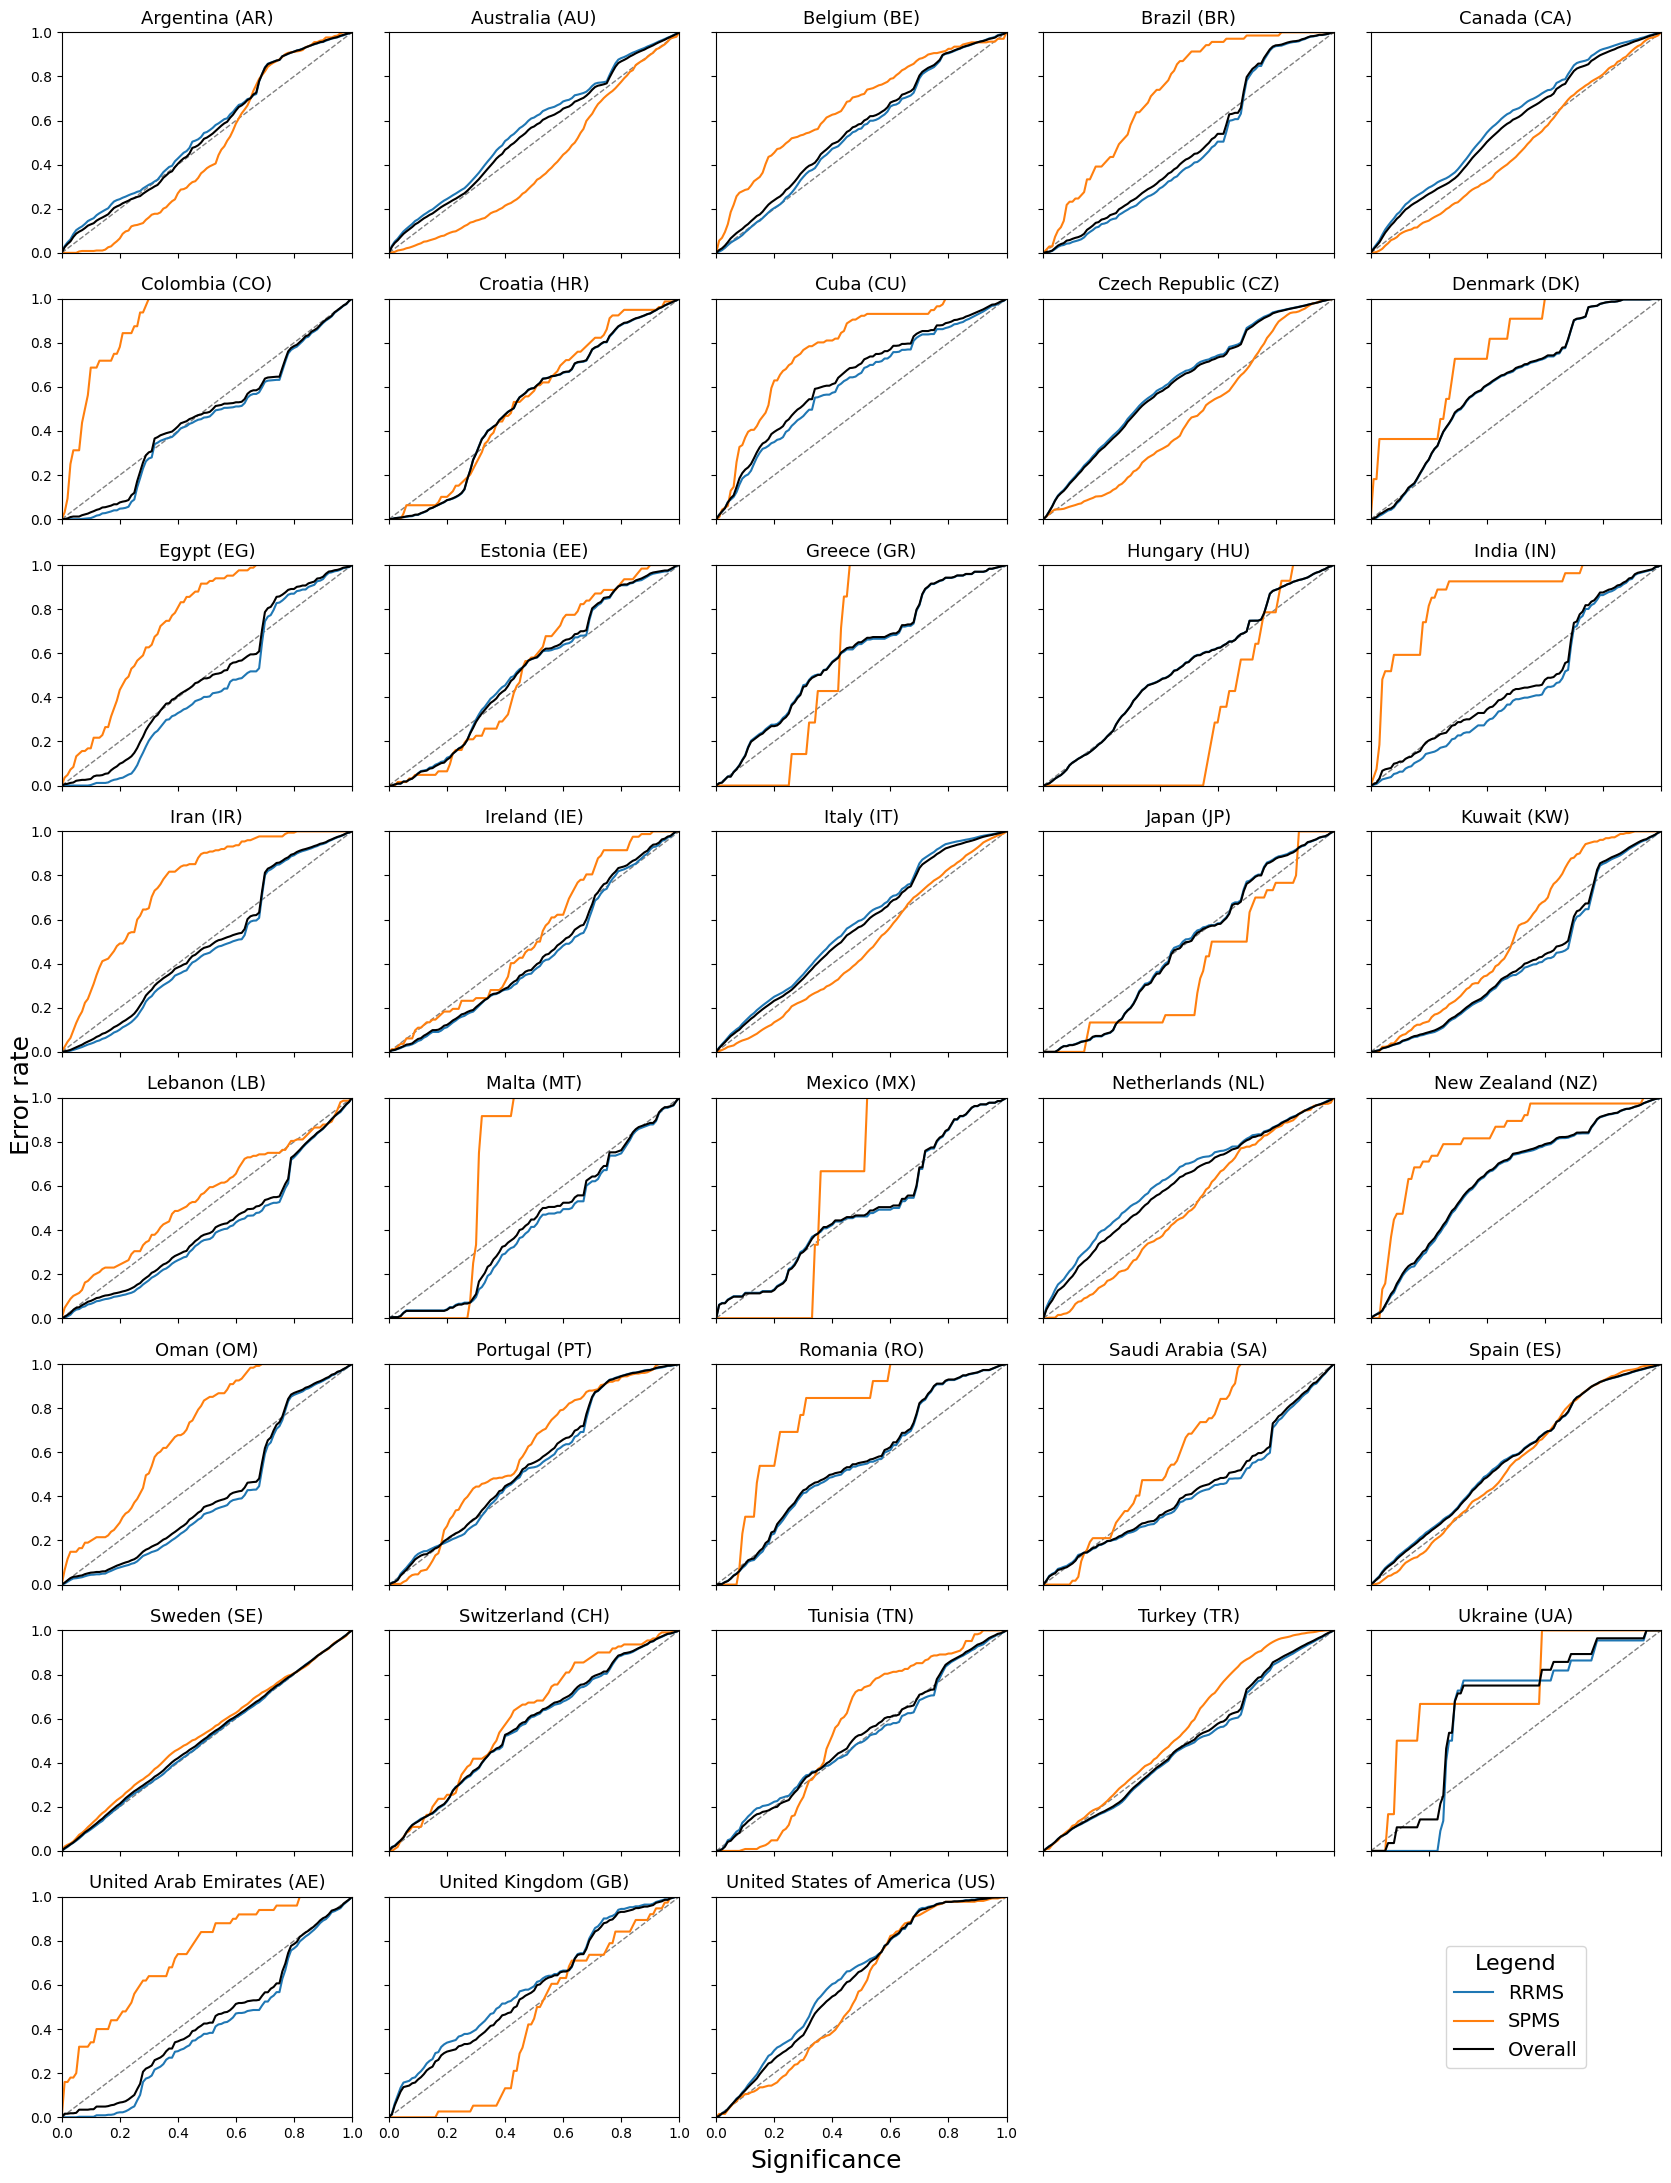

In [5]:
calibration_grid([(label(cc), swedish_results[cc]) for cc in countries], f"{FIG_DIR}/fig2_swedish_model_calibration.png")

## Global vs country-specific vs hybrid (Figure 3, Supplementary Figures 1-4)

In [6]:
strategy = pd.DataFrame({label(cc): {"Global": weighted_jsd(global_results[cc]),
                                     "Country-specific": weighted_jsd(country_specific_results[cc][cc]),
                                     "Hybrid": weighted_jsd(hybrid_results[cc][cc])} for cc in trainable}).T
strategy["Lowest"] = strategy.idxmin(axis=1)
strategy

,Global,Country-specific,Hybrid,Lowest
Australia (AU),0.022674,0.017482,0.004632,Hybrid
Belgium (BE),0.066724,0.074072,0.028650,Hybrid
Canada (CA),0.005797,0.016572,0.001657,Hybrid
Switzerland (CH),0.074145,0.110277,0.075645,Global
Czech Republic (CZ),0.032712,0.035002,0.013671,Hybrid
Egypt (EG),0.131378,0.043298,0.018940,Hybrid
Spain (ES),0.017816,0.025400,0.008012,Hybrid
United Kingdom (GB),0.116030,0.088140,0.102749,Country-specific
Iran (IR),0.227889,0.038646,0.041434,Country-specific
Italy (IT),0.008655,0.009657,0.003271,Hybrid


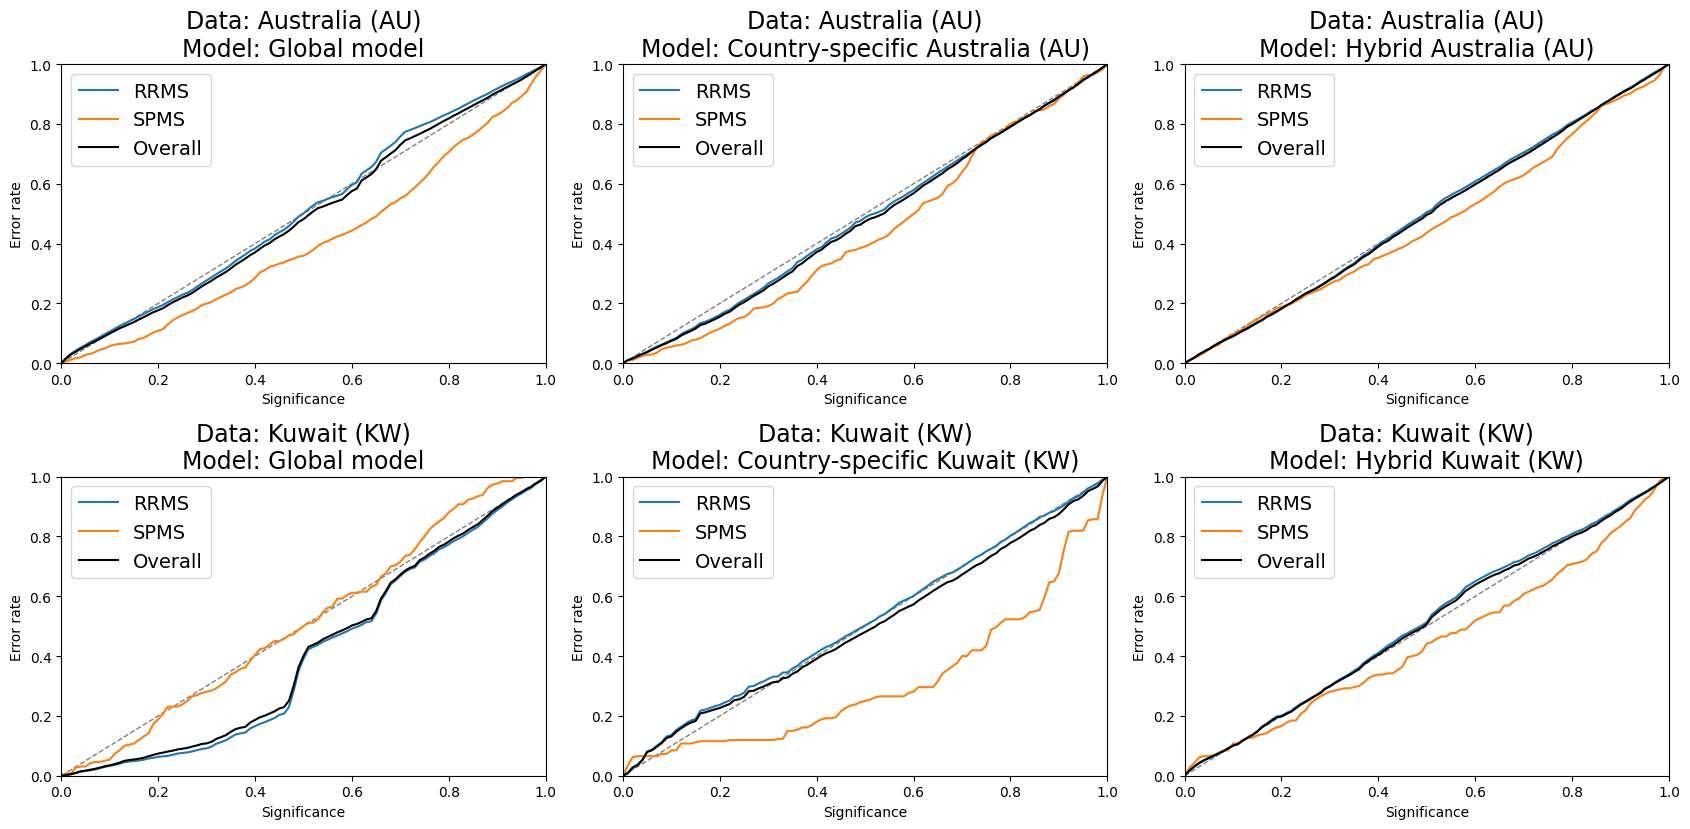

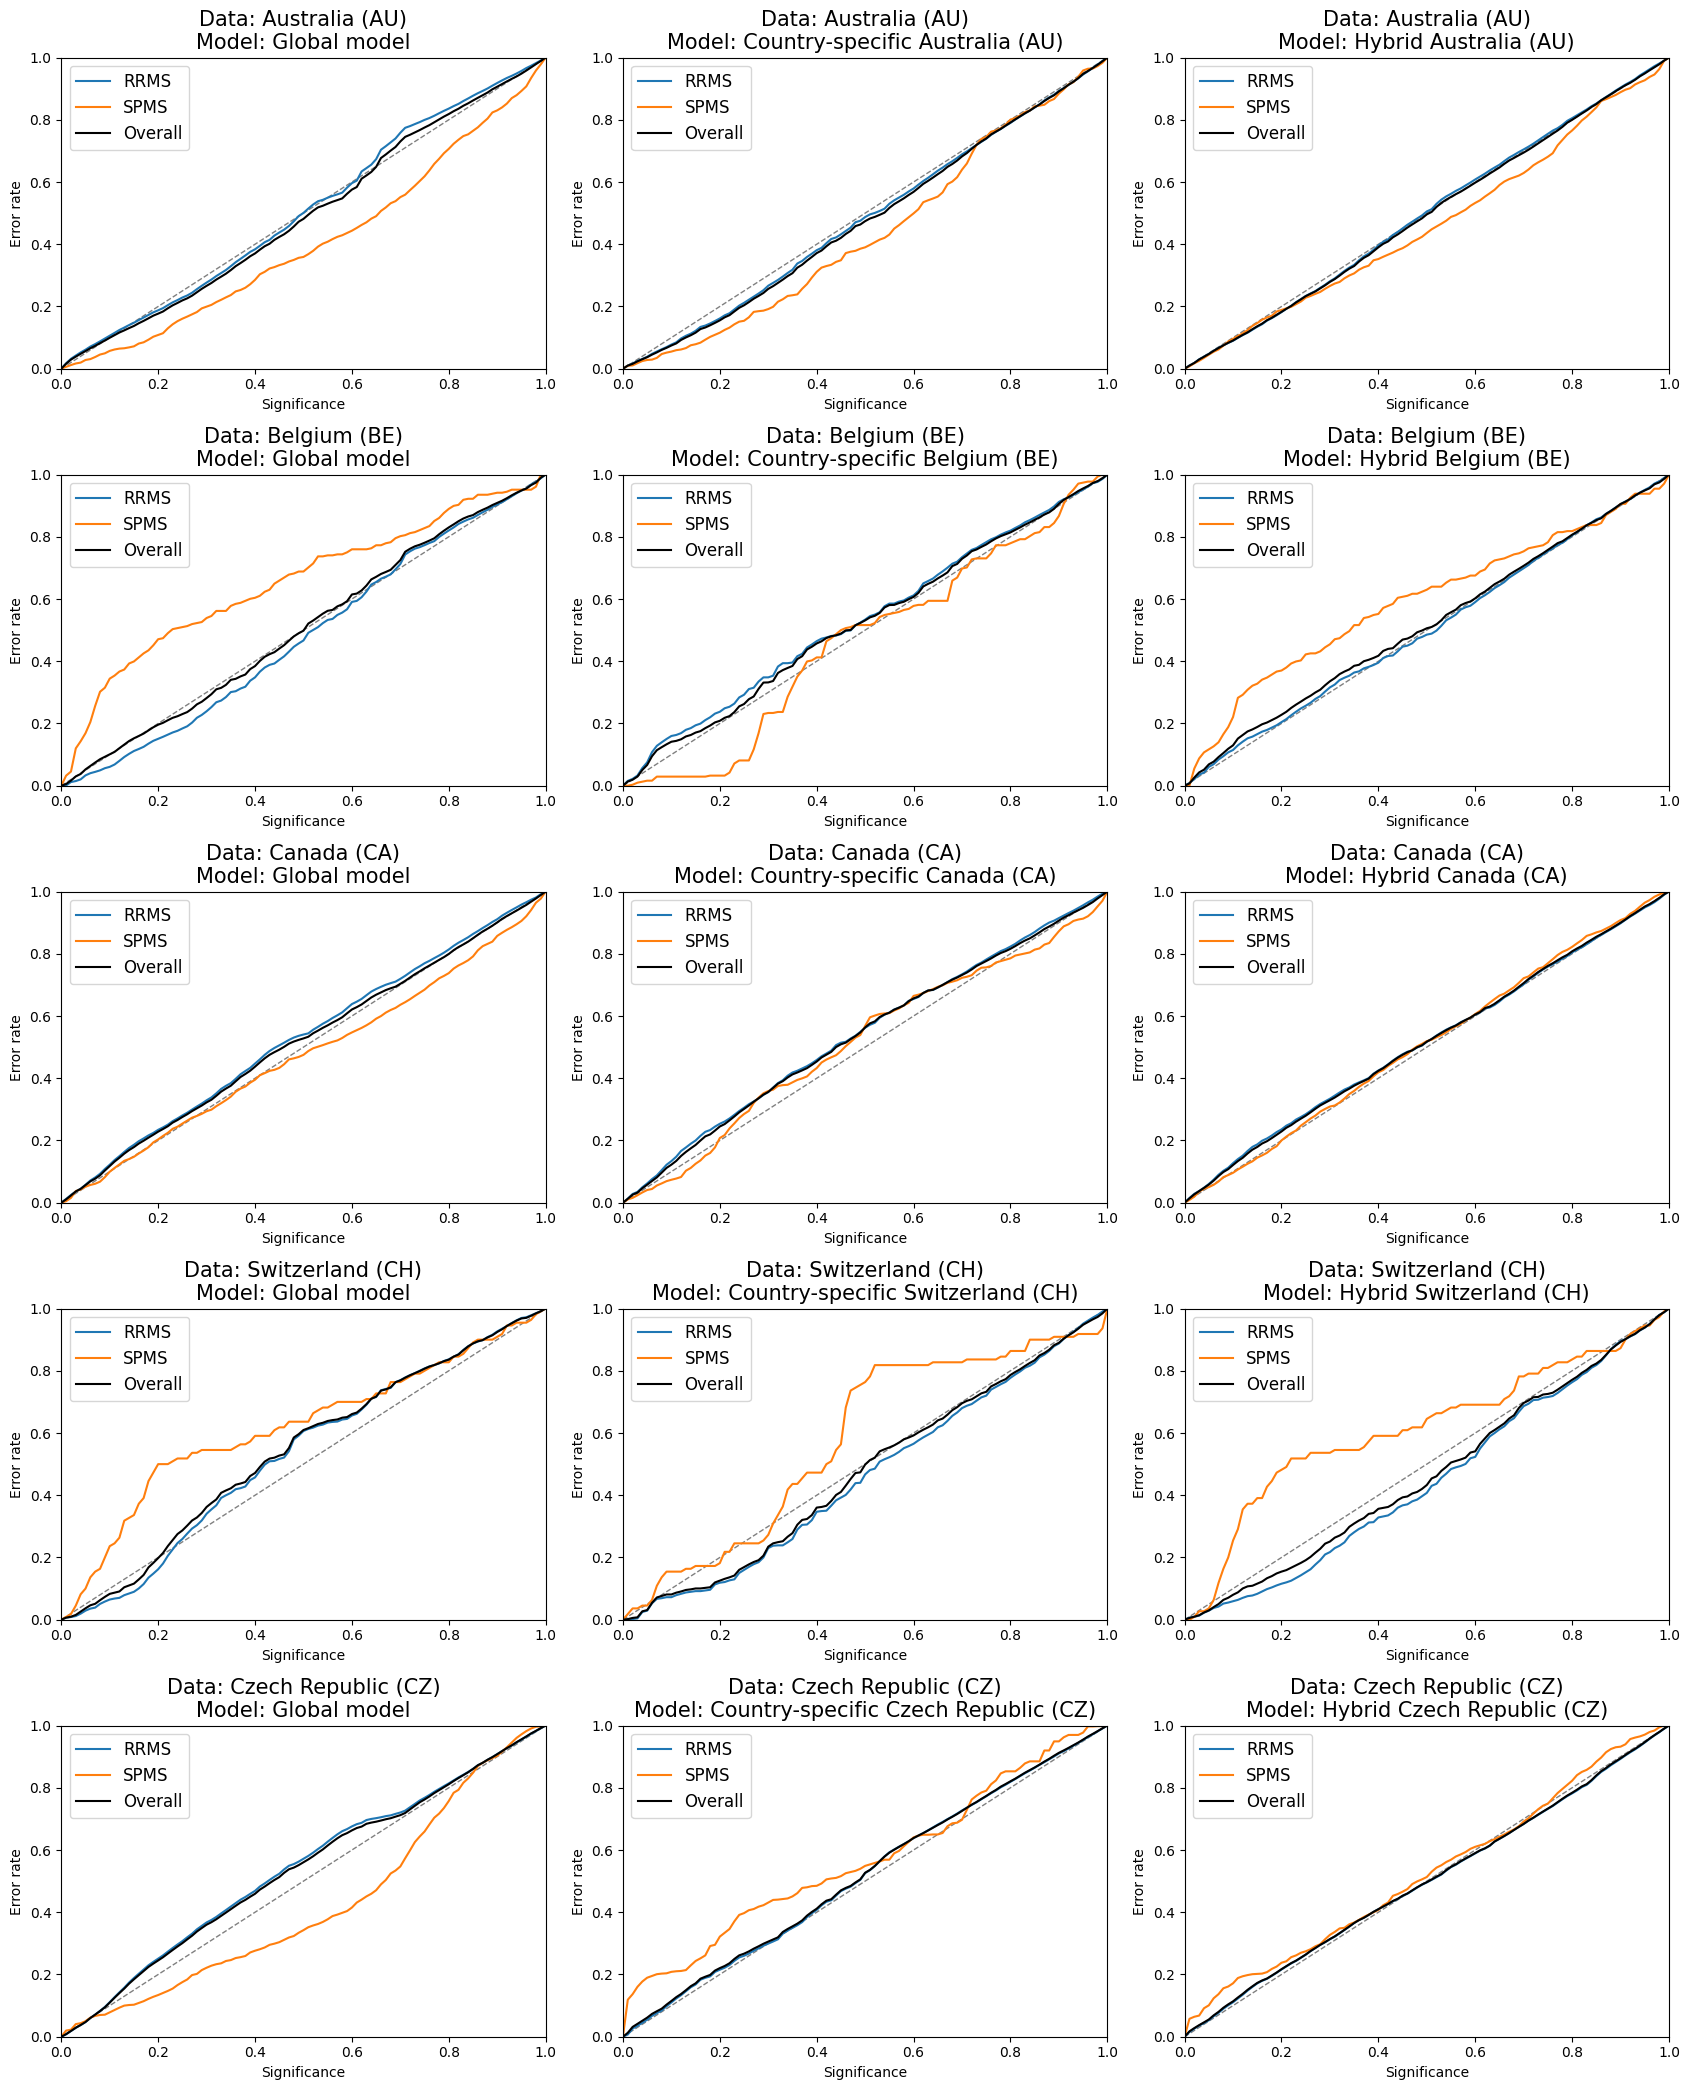

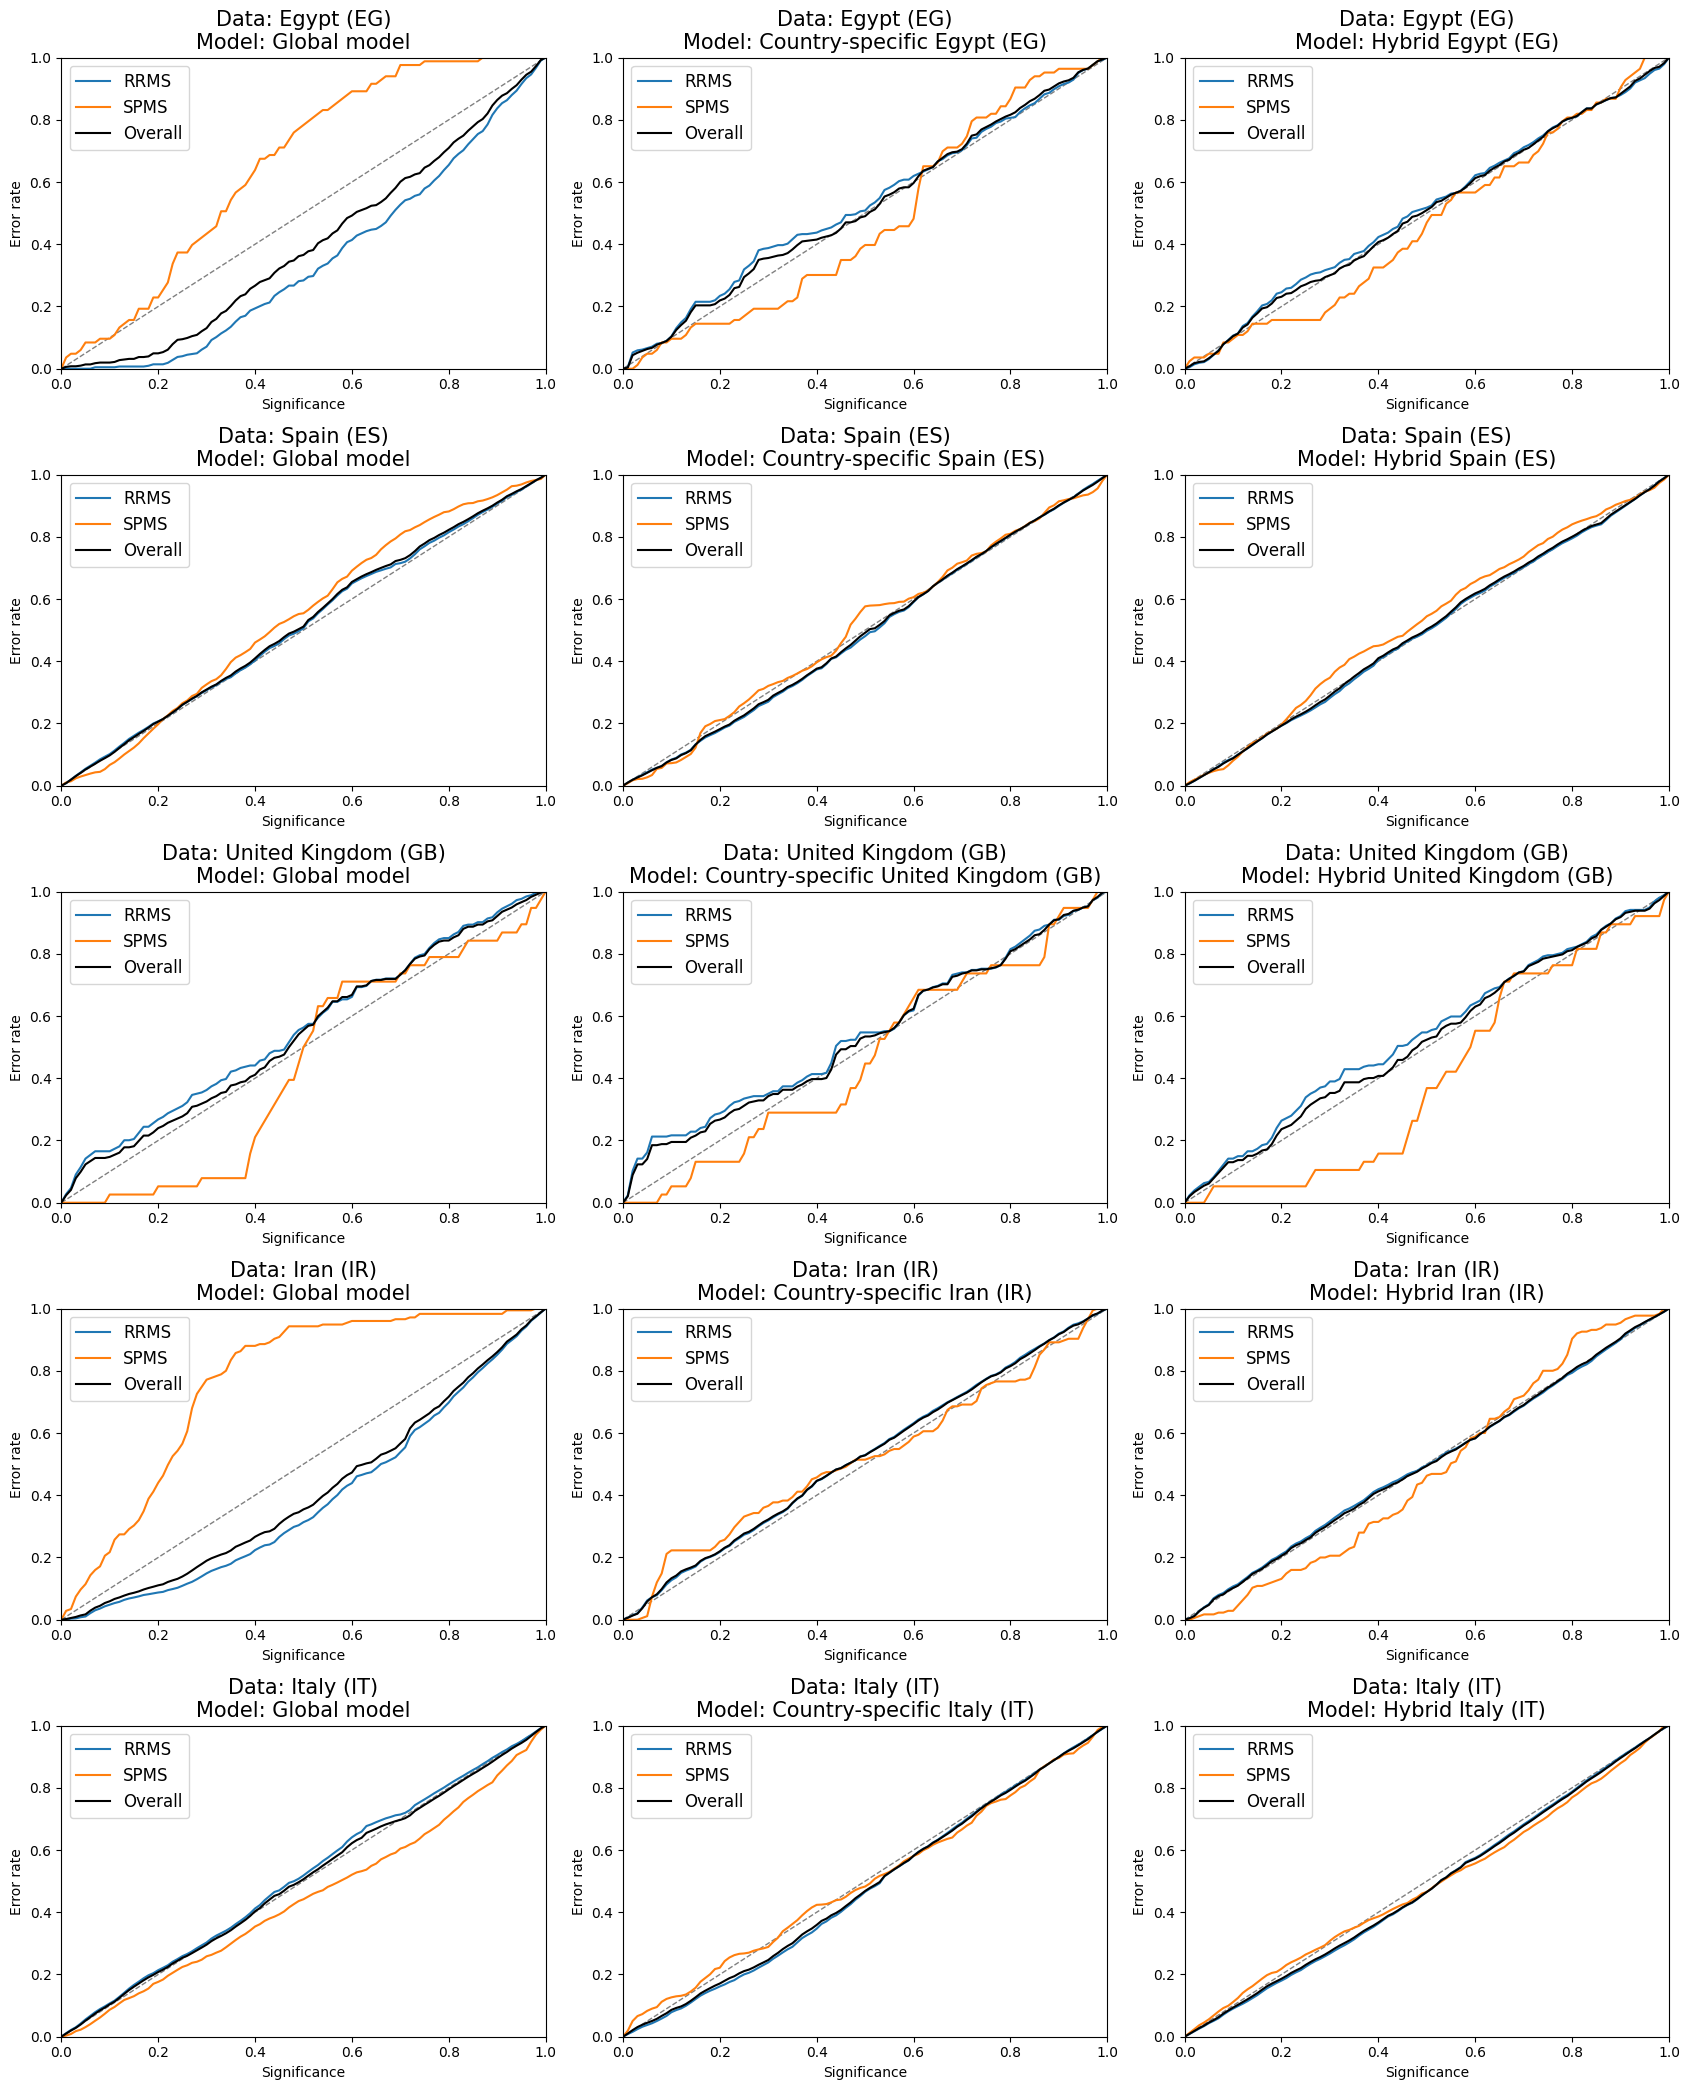

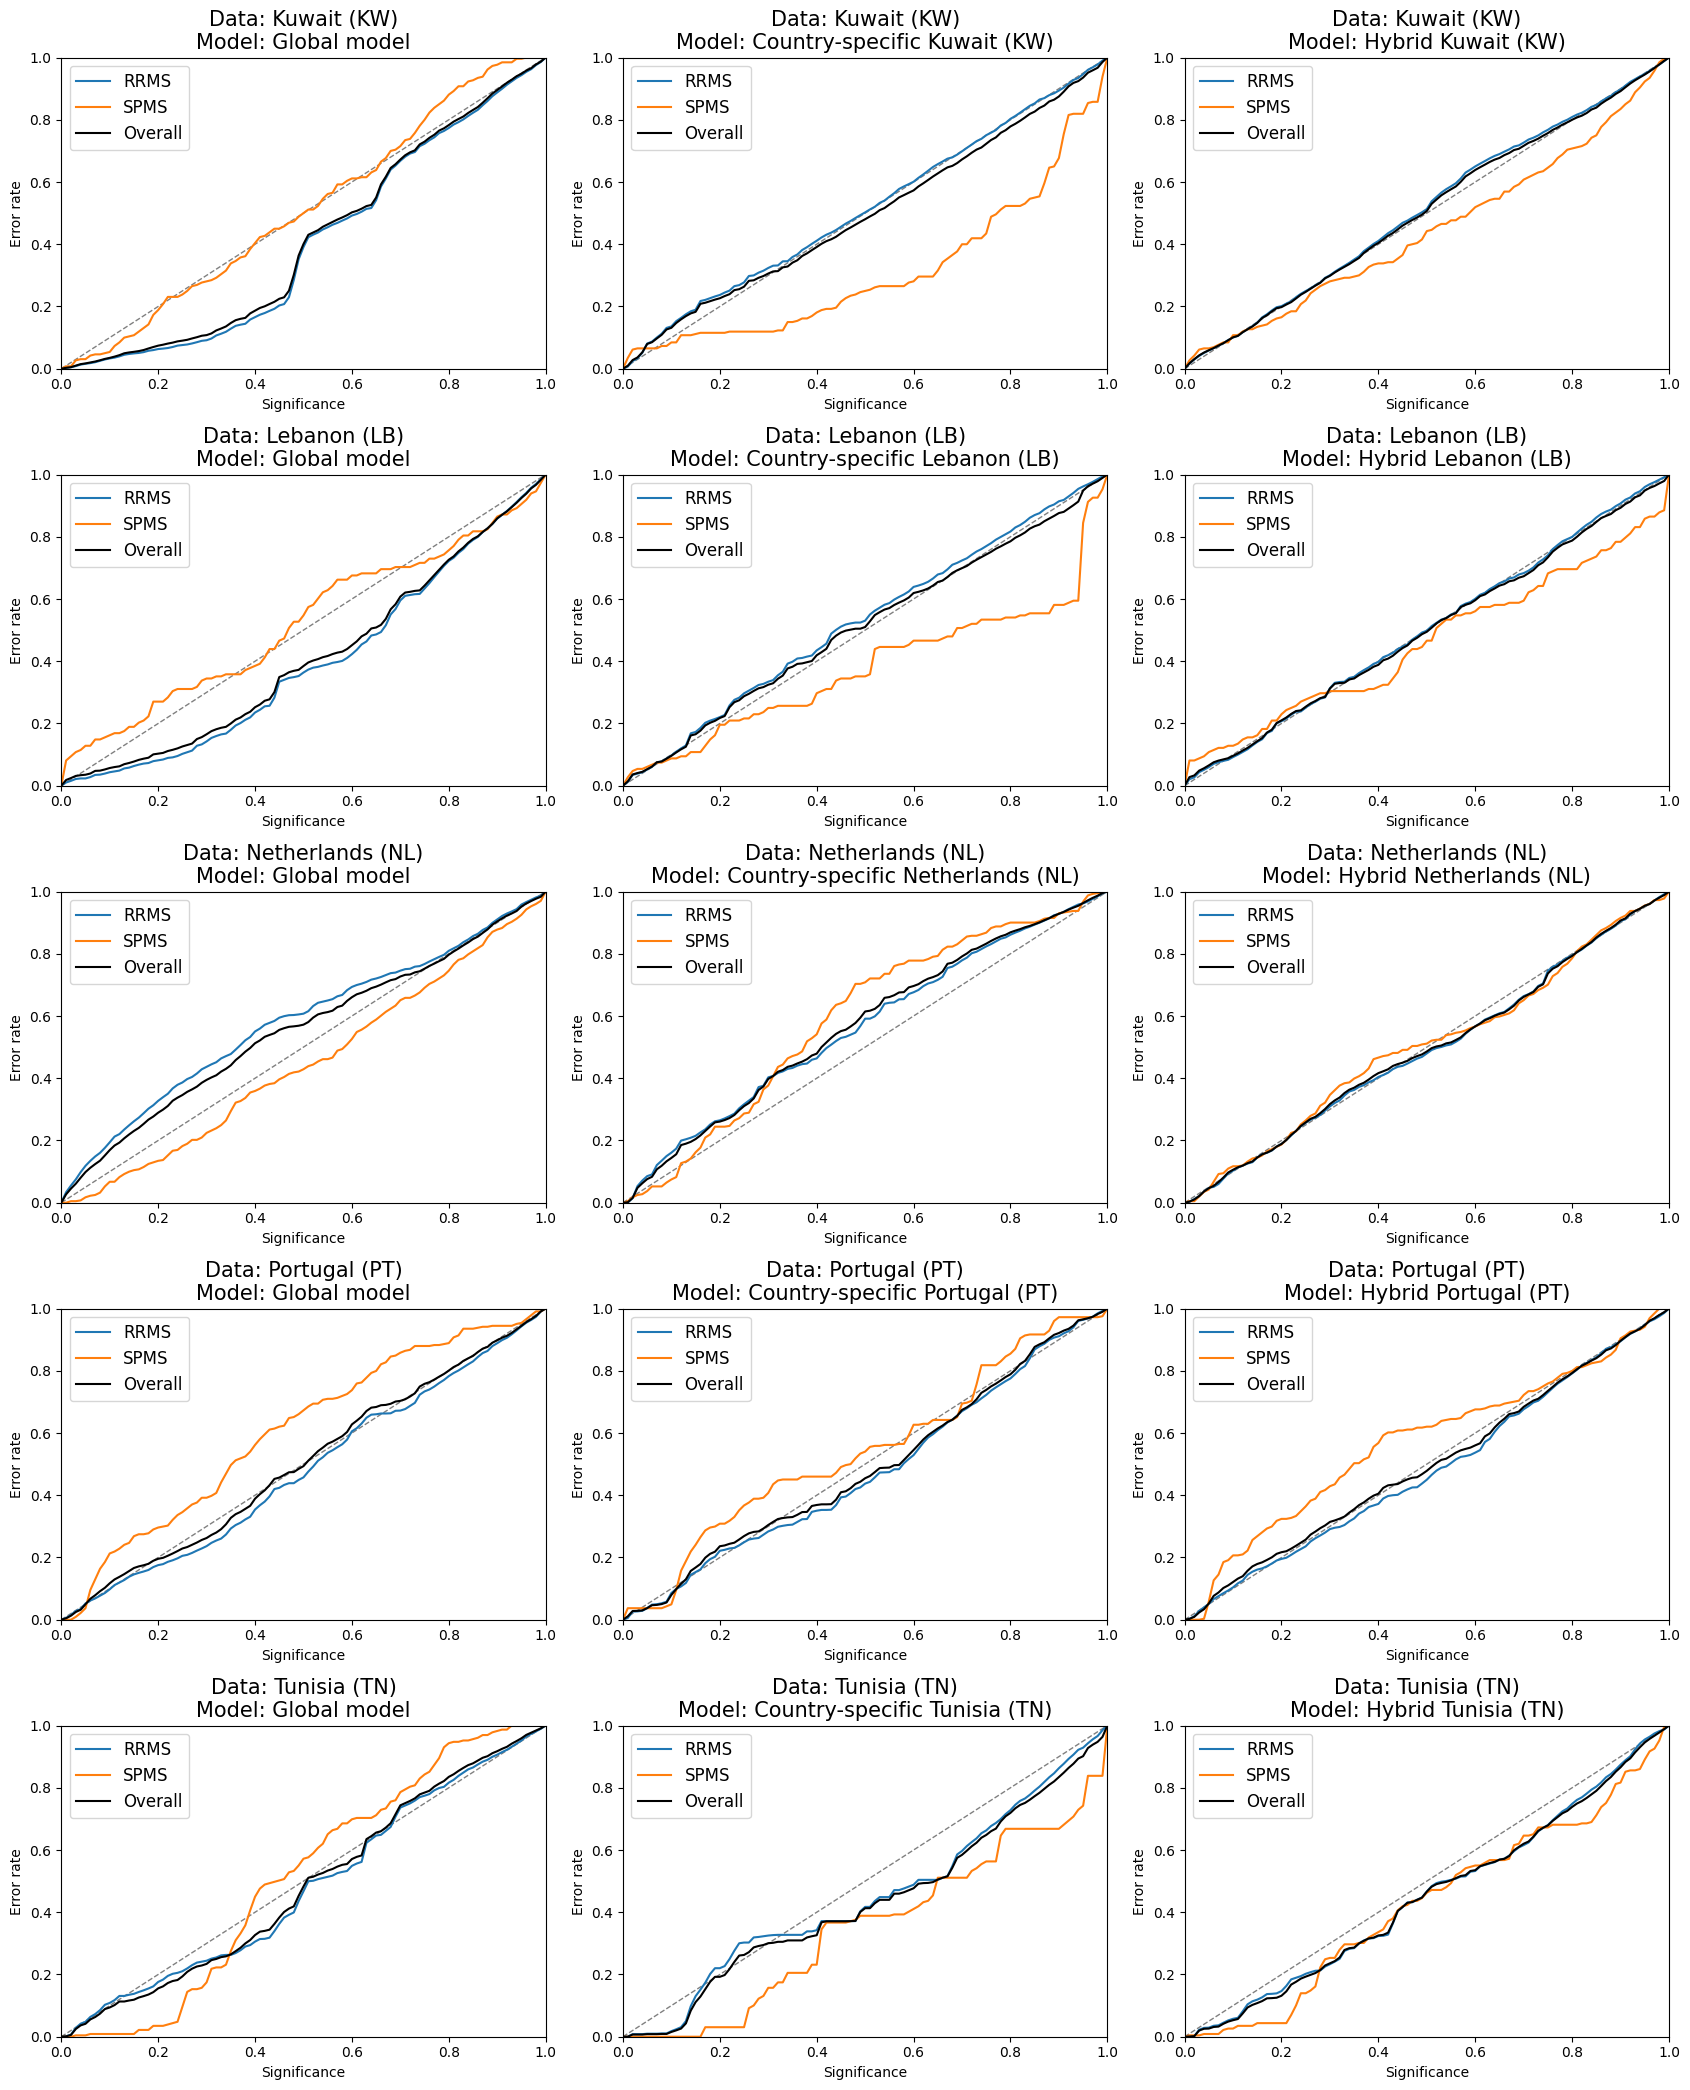

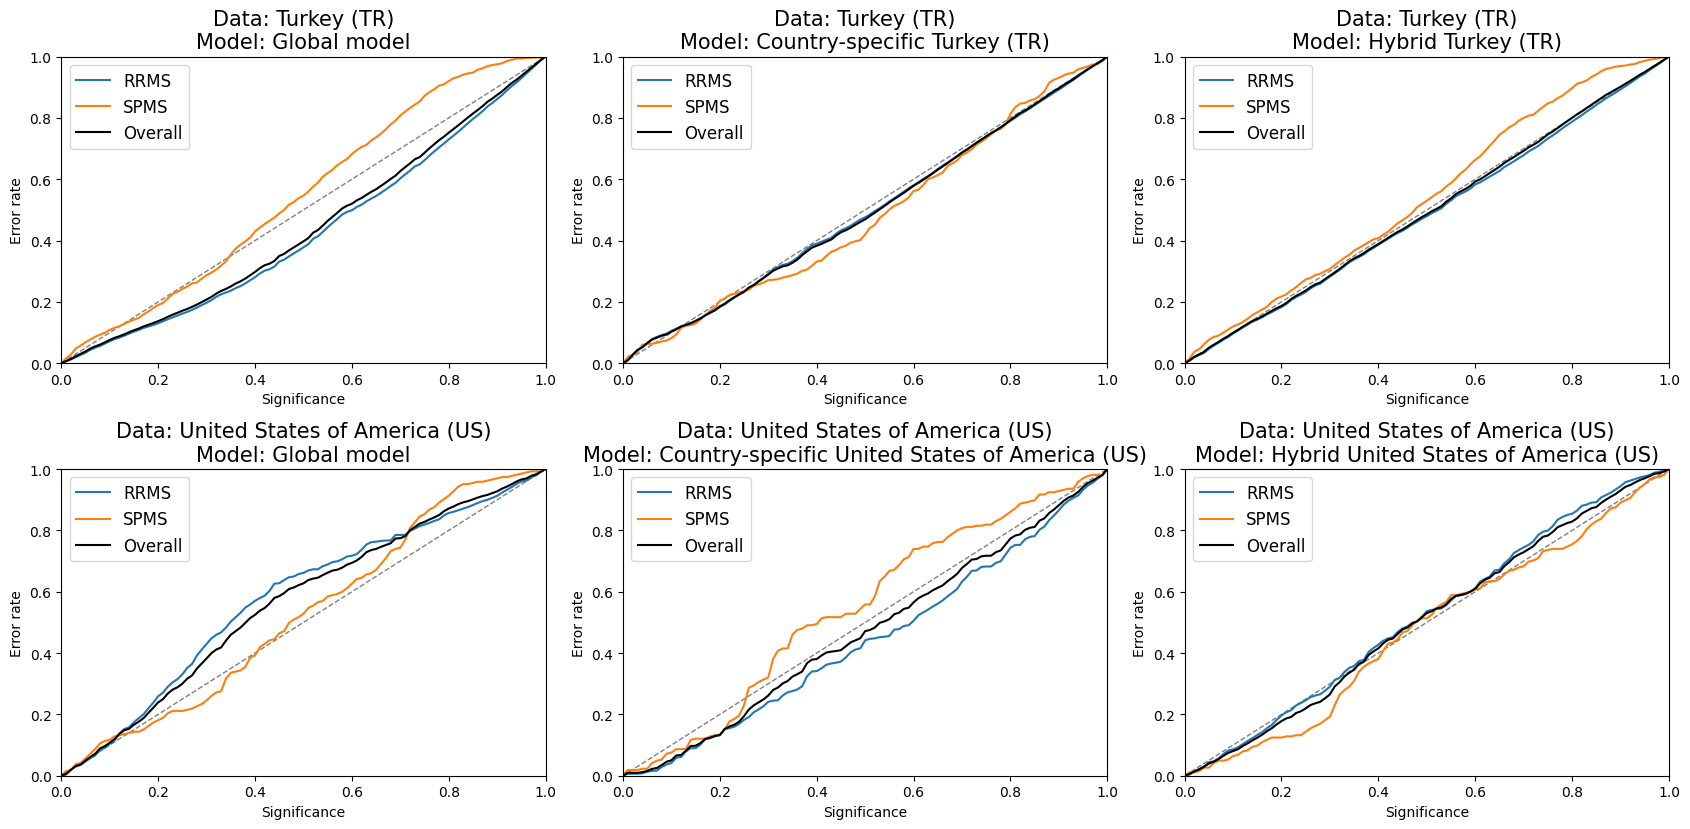

In [7]:
def strategy_plot(ccs, path, fontsize=15):
    fig, axes = plt.subplots(len(ccs), 3, figsize=(17, 4.2 * len(ccs)), squeeze=False)
    for row, cc in zip(axes, ccs):
        panels = [("Global model", global_results[cc]),
                  (f"Country-specific {label(cc)}", country_specific_results[cc][cc]),
                  (f"Hybrid {label(cc)}", hybrid_results[cc][cc])]
        for ax, (name, entry) in zip(row, panels):
            plot_calibration(ax, entry, f"Data: {label(cc)}\nModel: {name}", fontsize)
            ax.legend(fontsize=fontsize - 3)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


# Australia and Kuwait in the paper
fig3 = ["AU", "KW"] if {"AU", "KW"} <= set(trainable) else trainable[:2]
strategy_plot(fig3, f"{FIG_DIR}/fig3_strategy_comparison.png", fontsize=17)
for i in range(0, len(trainable), 5):
    strategy_plot(trainable[i:i + 5], f"{FIG_DIR}/supp_fig{i // 5 + 1}_strategy_comparison.png")

## JSD matrix and model assignment (Figure 4)

Training countries keep their own hybrid model, Sweden keeps the Swedish model, and every other country gets the model with the lowest JSD (blue boxes).

Japan (JP): lowest is Hybrid BE (0.1852), using Hybrid CZ (0.1861) instead - near tie, see NEAR_TIE_SWITCH


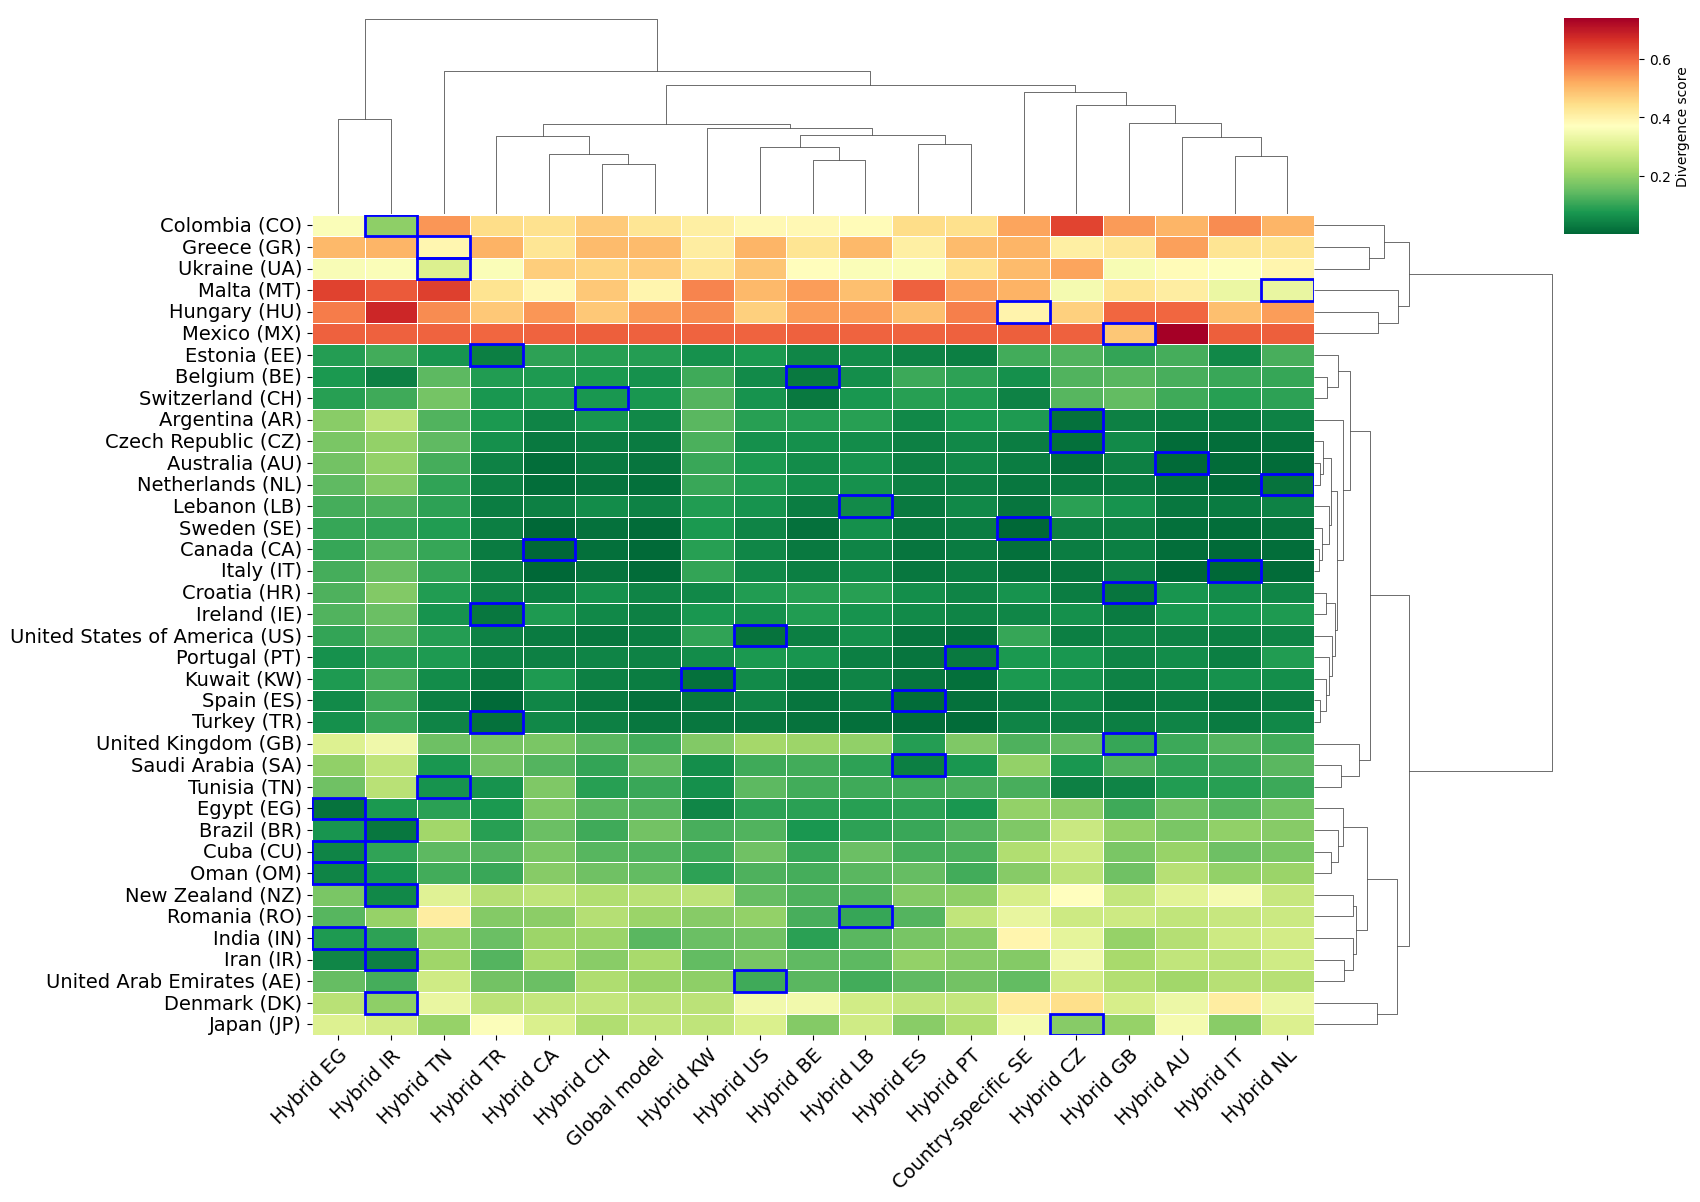

,Model,JSD
Argentina (AR),Hybrid CZ,0.018797
Australia (AU),Hybrid AU,0.004632
Belgium (BE),Hybrid BE,0.028650
Brazil (BR),Hybrid IR,0.025567
Canada (CA),Hybrid CA,0.001657
Colombia (CO),Hybrid IR,0.194495
Croatia (HR),Hybrid GB,0.023147
Cuba (CU),Hybrid EG,0.046911
Czech Republic (CZ),Hybrid CZ,0.013671
Denmark (DK),Hybrid IR,0.194917


In [8]:
matrix = jsd_matrix(entry_for, countries, trainable)
assignment = assign_models(matrix, trainable)
assigned_jsd = {cc: matrix.loc[label(cc), m] for cc, m in assignment.items()}
with open(f"{OUT_DIR}/model_assignment.json", "w") as f:
    json.dump(assignment, f, indent=1)

g = sns.clustermap(matrix.dropna(), cmap="RdYlGn_r", figsize=(15, 12), linewidths=0.5, linecolor="white",
                   cbar_kws={"label": "Divergence score"})
for i, country in enumerate(g.data2d.index):
    j = list(g.data2d.columns).index(assignment[code_of(country)])
    g.ax_heatmap.add_patch(patches.Rectangle((j, i), 1, 1, lw=2, edgecolor="blue", facecolor="none"))

# labels on the left, dendrogram on the right
ax = g.ax_heatmap
ax.yaxis.set_ticks_position("left")
ax.yaxis.set_label_position("left")
ax.tick_params(axis="y", labelleft=True, labelright=False, labelsize=14)
ax.tick_params(axis="x", labelsize=14)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
heat, den = ax.get_position(), g.ax_row_dendrogram.get_position()
g.ax_row_dendrogram.set_position([heat.x1, heat.y0, den.width, heat.height])
g.ax_row_dendrogram.invert_xaxis()
if g.cax is not None:
    cax = g.cax.get_position()
    g.cax.set_position([heat.x1 + den.width, cax.y0, cax.width, cax.height])
g.figure.savefig(f"{FIG_DIR}/fig4_jsd_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame({"Model": {label(cc): m for cc, m in assignment.items()},
              "JSD": {label(cc): assigned_jsd[cc] for cc in assignment}}).sort_index()

## Readiness

A country is ready if its assigned model has JSD <= 0.03, or if it is in `READY_BY_INSPECTION`.

In [9]:
ready = sorted(cc for cc in assignment if assigned_jsd[cc] <= JSD_THRESHOLD or cc in READY_BY_INSPECTION)
not_ready = sorted(set(assignment) - set(ready))
print("ready:", len(ready), ready)
print("not yet ready:", len(not_ready), not_ready)

ready: 23 ['AR', 'AU', 'BE', 'BR', 'CA', 'CZ', 'EE', 'EG', 'ES', 'HR', 'IE', 'IN', 'IR', 'IT', 'KW', 'LB', 'NL', 'OM', 'PT', 'SE', 'TN', 'TR', 'US']
not yet ready: 15 ['AE', 'CH', 'CO', 'CU', 'DK', 'GB', 'GR', 'HU', 'JP', 'MT', 'MX', 'NZ', 'RO', 'SA', 'UA']


## Calibration with the assigned models (Supplementary Figure 5)

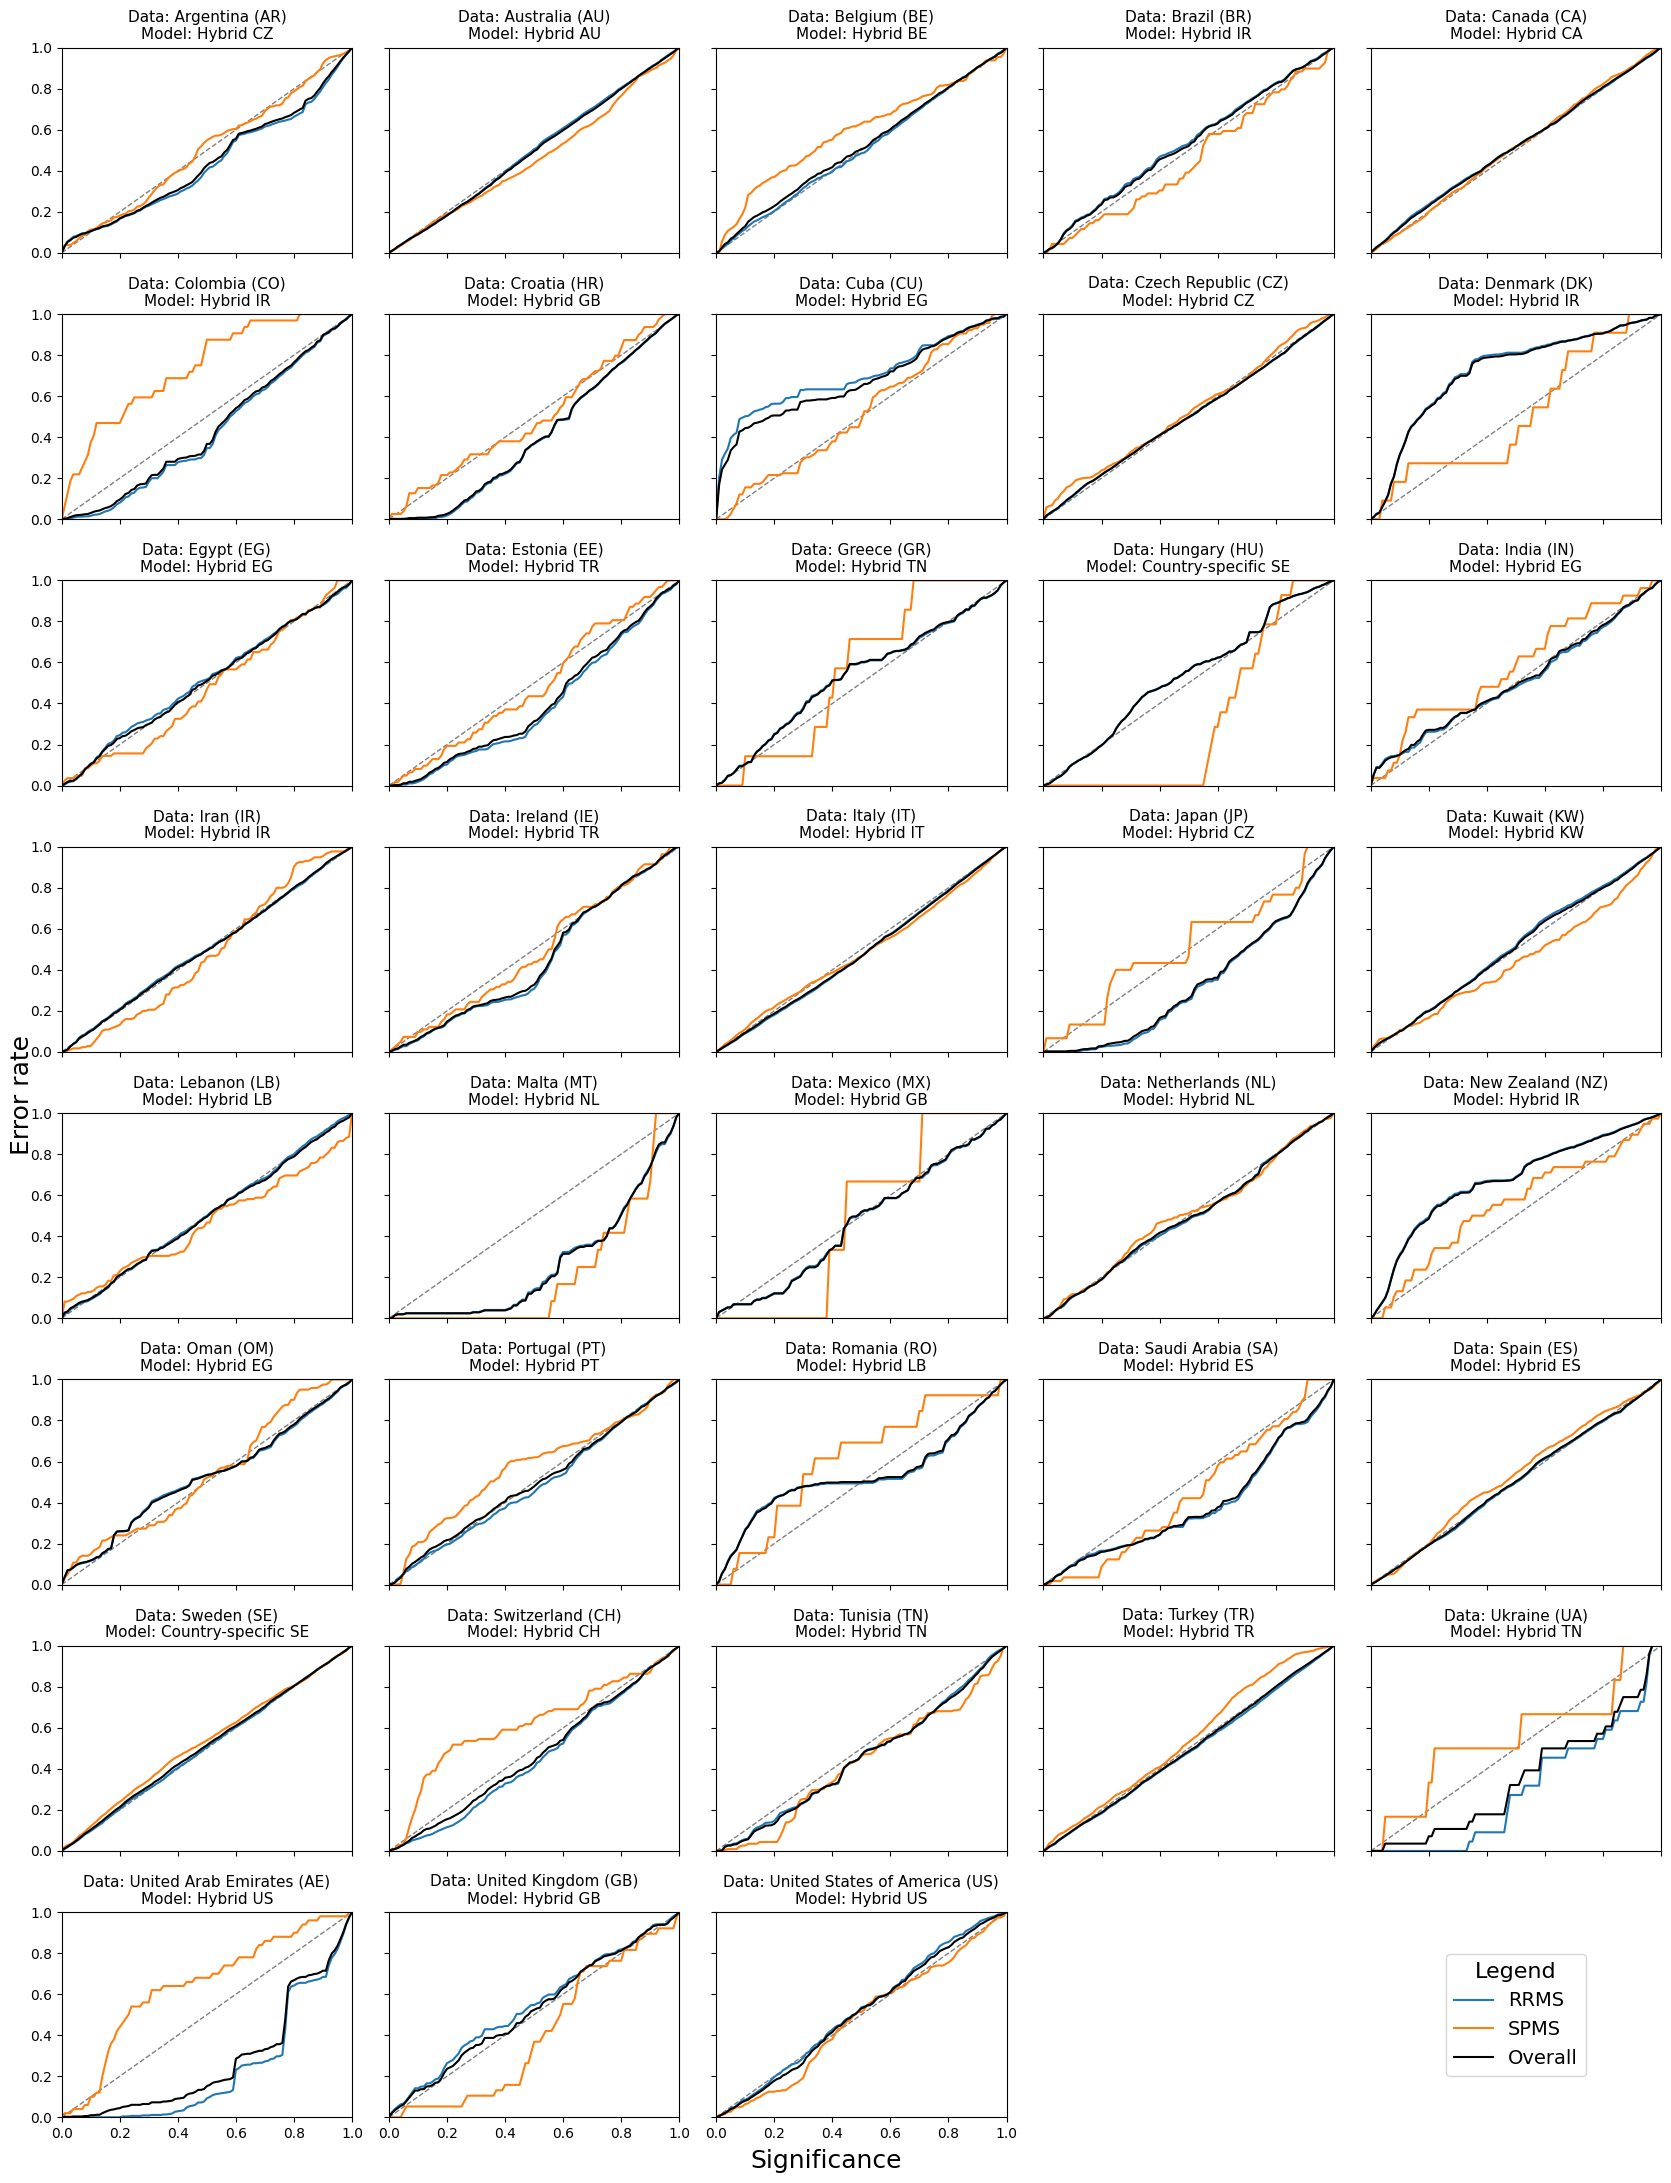

In [10]:
calibration_grid([(f"Data: {label(cc)}\nModel: {assignment[cc]}", entry_for(assignment[cc], cc)) for cc in sorted(assignment, key=label)],
                 f"{FIG_DIR}/supp_fig5_assigned_model_calibration.png", title_size=11)

## Prediction sets per country (Supplementary Table 3)

Uses the significance level that gives the most single-label predictions for each country. Ready countries first, then the ones that are not yet ready.

In [11]:
rows, significance = [], {}
for cc in sorted(assignment, key=label):
    p, y = as_arrays(entry_for(assignment[cc], cc))
    eps = best_significance(p)
    significance[cc] = round(float(eps), 2)
    inc = p > eps
    size = inc.sum(axis=1)
    row = {("", "Model name"): assignment[cc], ("", "Significance"): round(eps, 2)}
    for cls, name in [(0, "RRMS"), (1, "SPMS")]:
        m = y == cls
        row[(f"{name} - diagnosed", "RRMS")] = int(((size == 1) & inc[:, 0] & m).sum())
        row[(f"{name} - diagnosed", "SPMS")] = int(((size == 1) & inc[:, 1] & m).sum())
        row[(f"{name} - diagnosed", "Multi label")] = int(((size == 2) & m).sum())
        row[(f"{name} - diagnosed", "Empty label")] = int(((size == 0) & m).sum())
    rows.append(pd.Series(row, name=label(cc)))
sets = pd.DataFrame(rows)
sets.columns = pd.MultiIndex.from_tuples(sets.columns)
sets = pd.concat([sets.loc[[label(cc) for cc in sorted(ready, key=label)]],
                  sets.loc[[label(cc) for cc in sorted(not_ready, key=label)]]])
sets.to_csv(f"{TABLE_DIR}/supp_table3_prediction_sets.csv")

for name, ccs in [("ready", ready), ("not yet ready", not_ready)]:
    part = sets.loc[[label(cc) for cc in ccs]].drop(columns="", level=0).astype(int)
    total = part.to_numpy().sum()
    correct = part[("RRMS - diagnosed", "RRMS")].sum() + part[("SPMS - diagnosed", "SPMS")].sum()
    wrong = part[("RRMS - diagnosed", "SPMS")].sum() + part[("SPMS - diagnosed", "RRMS")].sum()
    if total:
        print(f"{name}: {correct / total:.1%} correct single-label, {wrong / total:.1%} wrong single-label")
sets

ready: 90.5% correct single-label, 9.0% wrong single-label
not yet ready: 87.5% correct single-label, 12.2% wrong single-label


\
                                        Model name Significance   
Argentina (AR)                           Hybrid CZ         0.07   
Australia (AU)                           Hybrid AU         0.10   
Belgium (BE)                             Hybrid BE         0.10   
Brazil (BR)                              Hybrid IR         0.09   
Canada (CA)                              Hybrid CA         0.10   
Croatia (HR)                             Hybrid GB         0.10   
Czech Republic (CZ)                      Hybrid CZ         0.07   
Egypt (EG)                               Hybrid EG         0.04   
Estonia (EE)                             Hybrid TR         0.08   
India (IN)                               Hybrid EG         0.04   
Iran (IR)                                Hybrid IR         0.09   
Ireland (IE)                             Hybrid TR         0.08   
Italy (IT)                               Hybrid IT         0.11   
Kuwait (KW)                              Hybrid KW         0.03   
Lebanon (LB)                             Hybrid LB         0.06   
Netherlands (NL)                         Hybrid NL         0.14   
Oman (OM)                                Hybrid EG         0.04   
Portugal (PT)                            Hybrid PT         0.10   
Spain (ES)                               Hybrid ES         0.11   
Sweden (SE)                    Country-specific SE         0.09   
Tunisia (TN)                             Hybrid TN         0.11   
Turkey (TR)                              Hybrid TR         0.08   
United States of America (US)            Hybrid US         0.15   
Colombia (CO)                            Hybrid IR         0.09   
Cuba (CU)                                Hybrid EG         0.04   
Denmark (DK)                             Hybrid IR         0.09   
Greece (GR)                              Hybrid TN         0.11   
Hungary (HU)                   Country-specific SE         0.10   
Japan (JP)                               Hybrid CZ         0.07   
Malta (MT)                               Hybrid NL         0.06   
Mexico (MX)                              Hybrid GB         0.07   
New Zealand (NZ)                         Hybrid IR         0.09   
Romania (RO)                             Hybrid LB         0.06   
Saudi Arabia (SA)                        Hybrid ES         0.11   
Switzerland (CH)                         Hybrid CH         0.11   
Ukraine (UA)                             Hybrid TN         0.10   
United Arab Emirates (AE)                Hybrid US         0.15   
United Kingdom (GB)                      Hybrid GB         0.11   

                              RRMS - diagnosed                                \
                                          RRMS  SPMS Multi label Empty label   
Argentina (AR)                            2357   247           4           0   
Australia (AU)                           10340  1013           0           8   
Belgium (BE)                              1650   206           0           8   
Brazil (BR)                                712    98           3           0   
Canada (CA)                               6546   960          46           0   
Croatia (HR)                              1963     3           0           0   
Czech Republic (CZ)                      18718  1577         213           0   
Egypt (EG)                                 413     8           1           1   
Estonia (EE)                               377     4           0           0   
India (IN)                                 255    31           0           0   
Iran (IR)                                 2252   245           7           0   
Ireland (IE)                               444    21           0           0   
Italy (IT)                               11599  1195           0          69   
Kuwait (KW)                               2602   112           7           0   
Lebanon (LB)                              1066    81           5           0   
Netherlands (NL)        

Per-country summary used by the app (`app/`): assigned model, JSD, readiness and significance level. Only aggregates. For the published run it is also copied to `files/model_outputs/published_reference/`.

In [12]:
summary = {cc: {"model": assignment[cc], "jsd": round(float(assigned_jsd[cc]), 4), "ready": cc in ready,
               "significance": significance[cc],
               "jsd_all_models": matrix.loc[label(cc)].round(4).dropna().to_dict()} for cc in sorted(assignment)}
for path in [f"{OUT_DIR}/country_summary.json"] + ([f"{MODEL_OUTPUTS_DIR}/published_reference/country_summary.json"] if published_run else []):
    with open(path, "w") as f:
        json.dump(summary, f, indent=1)

## Country clusters (Figure 5)

Hierarchical clustering (average linkage, 5 clusters) of the standardised JSD matrix. The map needs internet to download the Natural Earth country shapes.

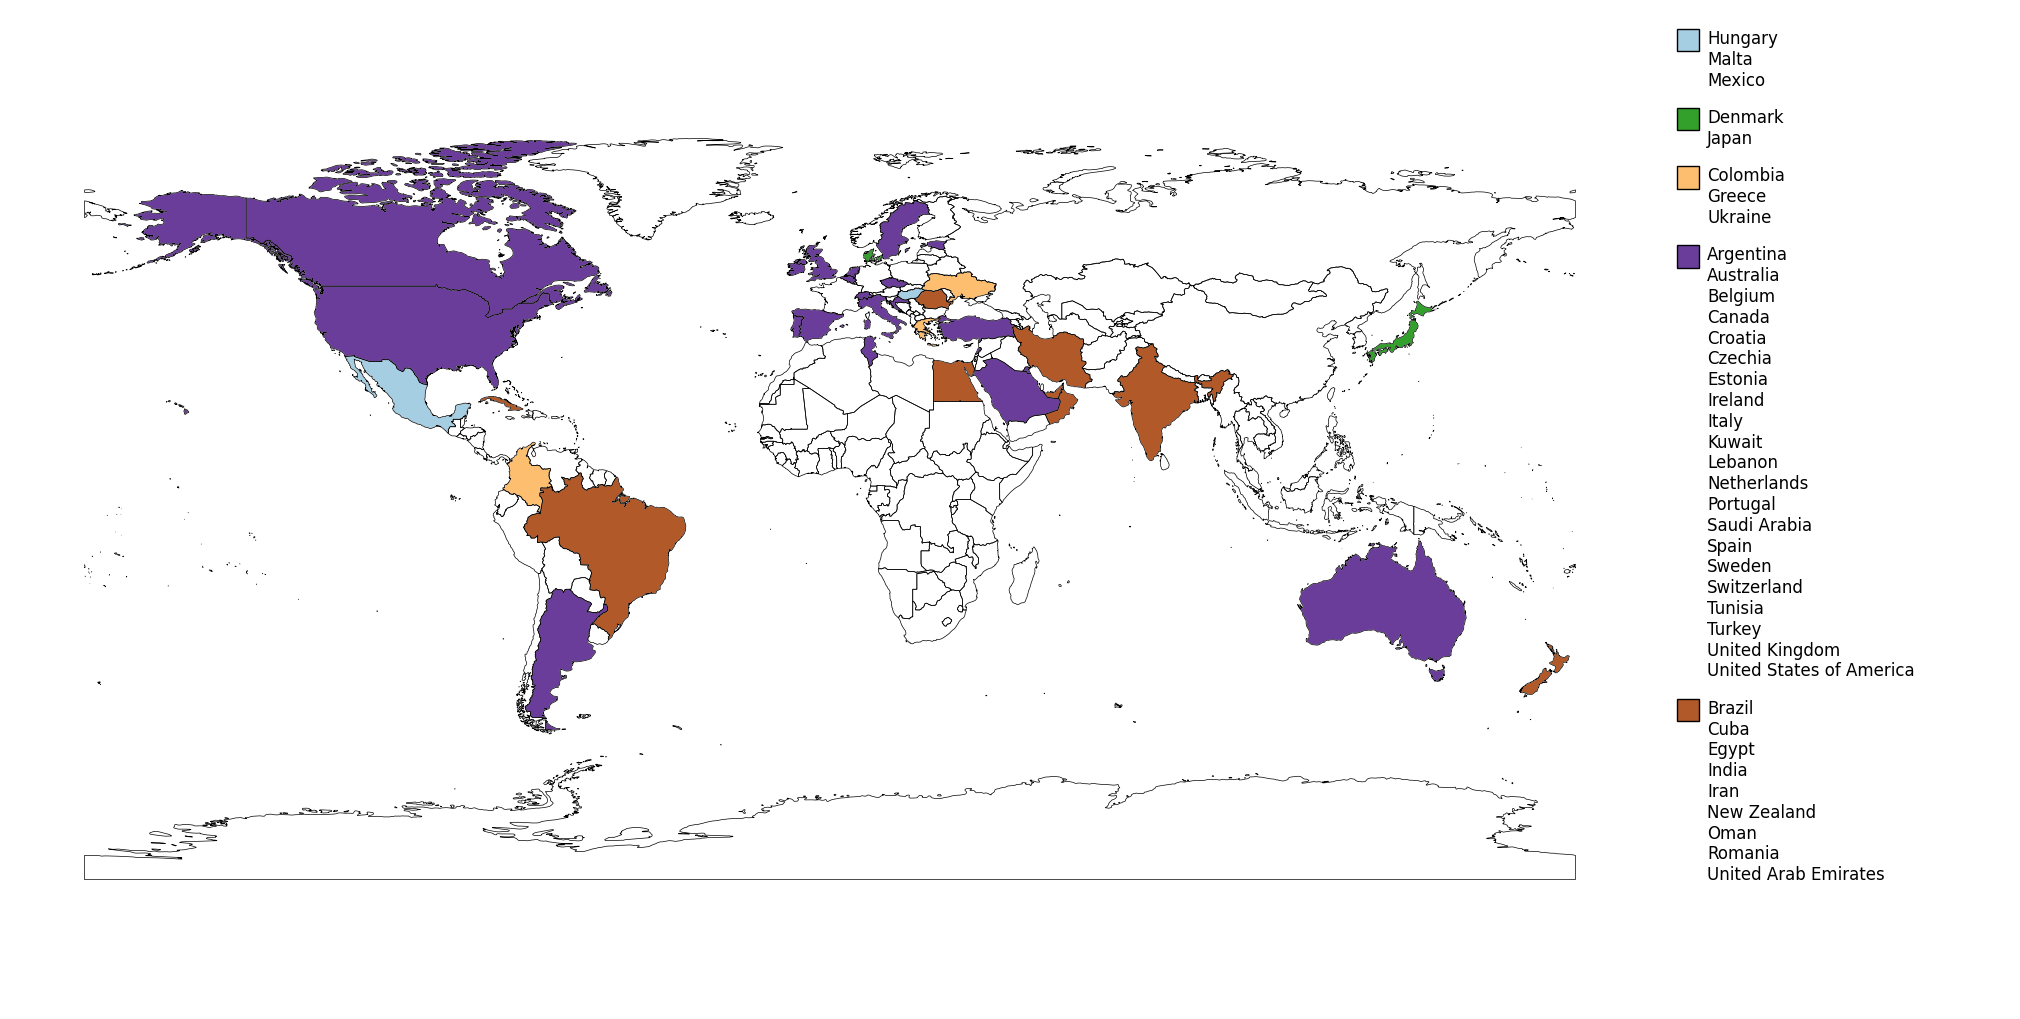

,ISO2,Cluster,Country
13,HU,0,Hungary (HU)
21,MT,0,Malta (MT)
22,MX,0,Mexico (MX)
9,DK,1,Denmark (DK)
18,JP,1,Japan (JP)
5,CO,2,Colombia (CO)
12,GR,2,Greece (GR)
34,UA,2,Ukraine (UA)
0,AR,3,Argentina (AR)
1,AU,3,Australia (AU)


In [13]:
complete = matrix.dropna()
n_clusters = min(5, len(complete) - 1)
clusters = pd.DataFrame({
    "ISO2": [code_of(c) for c in complete.index],
    "Cluster": AgglomerativeClustering(n_clusters=n_clusters, linkage="average").fit_predict(
        StandardScaler().fit_transform(complete.values)),
})

try:
    import geopandas as gpd
    from matplotlib.offsetbox import AnnotationBbox, DrawingArea, HPacker, TextArea, VPacker

    world = gpd.read_file("https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip")
    iso_col = next(c for c in ["ISO_A2_EH", "ISO_A2", "WB_A2", "iso_a2"] if c in world.columns)
    filled = world.merge(clusters, how="left", left_on=iso_col, right_on="ISO2")
    filled = filled[filled["Cluster"].notna()].astype({"Cluster": int})

    fig = plt.figure(figsize=(20, 10))
    ax_map = fig.add_axes([0, 0, 0.82, 1])
    ax_leg = fig.add_axes([0.83, 0, 0.17, 1])
    cmap = plt.get_cmap("Paired", n_clusters)
    world.boundary.plot(ax=ax_map, linewidth=0.5, color="black")
    filled.plot(column="Cluster", ax=ax_map, cmap=cmap, edgecolor="white", linewidth=0.5)
    ax_map.axis("off")

    legend_rows = []
    for k, names in filled.groupby("Cluster")["SOVEREIGNT"].apply(lambda s: sorted(set(s))).items():
        swatch = DrawingArea(16, 16, 0, 0)
        swatch.add_artist(patches.Rectangle((0, 0), 16, 16, facecolor=cmap(k), edgecolor="black"))
        legend_rows.append(HPacker(children=[swatch, TextArea("\n".join(names), textprops={"fontsize": 12})],
                                   align="top", pad=0, sep=6))
    ax_leg.axis("off")
    ax_leg.add_artist(AnnotationBbox(VPacker(children=legend_rows, align="left", pad=0, sep=14), (0.02, 0.98),
                                     xycoords="axes fraction", box_alignment=(0, 1), frameon=False))
    fig.savefig(f"{FIG_DIR}/fig5_world_map_clusters.png", dpi=300, bbox_inches="tight")
    plt.show()
except Exception as e:
    print("could not draw the map:", e)

clusters.assign(Country=[label(c) for c in clusters["ISO2"]]).sort_values(["Cluster", "Country"])

## SHAP (Supplementary Figures 9-11)

The SHAP values are not part of the published files. Notebook 2 computes them for a custom run (in `custom_run/shap/`); for the published results this section is skipped.

In [14]:
def load_shap(cc):
    path = f"{SHAP_DIR}/data_{cc}_model_{shap_tag(assignment[cc])}.joblib"
    if not os.path.exists(path):
        return None
    sv = joblib.load(path)
    if sv.values.ndim == 3:  # both classes saved, keep SPMS
        sv = sv[..., 1]
    sv.feature_names = FEATURE_NAMES
    return sv


shap_values = {cc: sv for cc in ready if (sv := load_shap(cc)) is not None}
shap_countries = sorted(shap_values, key=label)
if not os.path.isdir(SHAP_DIR):
    print(f"no SHAP values in {SHAP_DIR}, skipping")
else:
    missing = sorted(set(ready) - set(shap_values))
    print(f"SHAP for {len(shap_countries)} of {len(ready)} ready countries" + (f", missing: {missing}" if missing else ""))

for i in range(0, len(shap_countries), 8):
    batch = shap_countries[i:i + 8]
    fig, axes = plt.subplots(4, 2, figsize=(20, 15))
    axes = axes.flatten()
    for ax, cc in zip(axes, batch):
        plt.sca(ax)
        shap.plots.beeswarm(shap_values[cc], show=False, plot_size=None)
        ax.set_title(f"Data: {label(cc)}\nModel: {assignment[cc]}", fontsize=12)
    for ax in axes[len(batch):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/supp_figs9-11_shap_page{i // 8 + 1}.png", dpi=300, bbox_inches="tight")
    plt.show()

no SHAP values in files/shap, skipping


## Lorscheider criteria vs model (Table 2)

In [15]:
cm = pd.read_csv(f"{MODEL_OUTPUTS_DIR}/model_lor_cm.csv", index_col=0)
with open(f"{MODEL_OUTPUTS_DIR}/lor_pred_visit_diff_results.json") as f:
    visit_diffs = json.load(f)


def ratio(a, b):
    return a / b if b else 0.0


def metrics(tp, fn, fp, tn):
    sens, spec, ppv, npv = ratio(tp, tp + fn), ratio(tn, tn + fp), ratio(tp, tp + fp), ratio(tn, tn + fn)
    return {"Sensitivity": round(sens * 100), "Specificity": round(spec * 100), "PPV": round(ppv * 100),
            "NPV": round(npv * 100), "F1": round(ratio(2 * sens * ppv, sens + ppv), 2)}


rows = {}
for cc, r in cm.iterrows():
    if cc not in ready:
        continue
    pos = r["spms_gt"] + r["transition_gt"]
    if r["rrms_gt"] < 10 or pos < 10:
        continue
    lor_tp = r["spms_lor"] + r["transition_lor"]
    model_tp = r["spms"] + r["transition"]
    lor = metrics(lor_tp, pos - lor_tp, r["rrms_lor"], r["rrms_gt"] - r["rrms_lor"])
    model = metrics(model_tp, pos - model_tp, r["rrms"], r["rrms_gt"] - r["rrms"])
    rows[label(cc)] = {**{("Lorscheider criteria", k): v for k, v in lor.items()},
                       **{("Model", k): v for k, v in model.items()}}
table2 = pd.DataFrame(rows).T.sort_index()
table2.columns = pd.MultiIndex.from_tuples(table2.columns)
table2.to_csv(f"{TABLE_DIR}/table2_lorscheider_benchmark.csv")

missing = [cc for cc in ready if cc not in cm.index]
if missing:
    print("no Lorscheider counts for", missing)
print(len(table2), "countries")
display(table2)

# mean ± SD across countries, as reported in the text
table2.agg(["mean", "std"]).round(2)

22 countries


Lorscheider criteria                           \
                                       Sensitivity Specificity    PPV   NPV   
Argentina (AR)                                60.0        92.0   55.0  93.0   
Australia (AU)                                72.0        93.0   61.0  96.0   
Belgium (BE)                                  45.0        95.0   64.0  91.0   
Brazil (BR)                                   29.0       100.0  100.0  87.0   
Canada (CA)                                   72.0        92.0   72.0  92.0   
Croatia (HR)                                  31.0       100.0  100.0  97.0   
Czech Republic (CZ)                           70.0        93.0   50.0  97.0   
Egypt (EG)                                    18.0       100.0  100.0  85.0   
Estonia (EE)                                   0.0       100.0    0.0  81.0   
Iran (IR)                                     46.0        95.0   59.0  92.0   
Ireland (IE)                                  64.0       100.0  100.0  92.0   
Italy (IT)                                    66.0        92.0   65.0  92.0   
Kuwait (KW)                                   63.0        99.0   86.0  95.0   
Lebanon (LB)                                  54.0        99.0   93.0  92.0   
Netherlands (NL)                              64.0        85.0   59.0  88.0   
Oman (OM)                                     57.0        98.0   76.0  94.0   
Portugal (PT)                                 82.0        92.0   67.0  96.0   
Spain (ES)                                    75.0        91.0   60.0  95.0   
Sweden (SE)                                   70.0        95.0   90.0  84.0   
Tunisia (TN)                                  58.0        95.0   64.0  94.0   
Turkey (TR)                                   60.0        96.0   64.0  95.0   
United States of America (US)                 46.0        92.0   73.0  79.0   

                                          Model                            \
                                 F1 Sensitivity Specificity    PPV    NPV   
Argentina (AR)                 0.58       100.0        83.0   49.0  100.0   
Australia (AU)                 0.66        98.0        83.0   47.0  100.0   
Belgium (BE)                   0.53        97.0        76.0   42.0   99.0   
Brazil (BR)                    0.45       100.0        70.0   40.0  100.0   
Canada (CA)                    0.72        95.0        79.0   57.0   98.0   
Croatia (HR)                   0.48        94.0       100.0   94.0  100.0   
Czech Republic (CZ)            0.58        97.0        83.0   38.0  100.0   
Egypt (EG)                     0.31       100.0       100.0  100.0  100.0   
Estonia (EE)                   0.00       100.0       100.0  100.0  100.0   
Iran (IR)                      0.52       100.0        82.0   45.0  100.0   
Ireland (IE)                   0.78       100.0        95.0   82.0  100.0   
Italy (IT)                     0.66        98.0        83.0   58.0   99.0   
Kuwait (KW)                    0.73        97.0        93.0   66.0  100.0   
Lebanon (LB)                   0.68        96.0        88.0   61.0   99.0   
Netherlands (NL)               0.61        89.0        75.0   54.0   95.0   
Oman (OM)                      0.65       100.0        89.0   55.0  100.0   
Portugal (PT)                  0.73       100.0        77.0   46.0  100.0   
Spain (ES)                     0.66        97.0        81.0   47.0   99.0   
Sweden (SE)                    0.79        97.0        86.0   80.0   98.0   
Tunisia (TN)                   0.61       100.0        91.0   63.0  100.0   
Turkey (TR)                    0.62        97.0        87.0   50.0  100.0   
United States of America (US)  0.56       100.0        74.0   64.0  100.0   

                                     
                                 F1  
Argentina (AR)                 0.66  
Australia (AU)                 0.64  
Belgium (BE)                   0.59  
Brazil (BR)                    0.58  
Canada (CA)                    0.71  
Croatia (HR)      

Lorscheider criteria                                       Model  \
              Sensitivity Specificity    PPV    NPV    F1 Sensitivity   
mean                54.64       95.18  70.82  91.23  0.59       97.82   
std                 20.09        4.00  22.79   5.12  0.17        2.72   

                                      
     Specificity    PPV    NPV    F1  
mean       85.23  60.82  99.41  0.74  
std         8.65  18.96   1.18  0.13

## Timing of the detected transitions (Supplementary Table 4, Supplementary Figures 6-8)

For pwMS-T: number of visits between the first SPMS visit of each method and the clinician's. 0 = exact, ±1 = one visit off, < -1 early, > 1 late. Ready countries with at least 5 pwMS-T.

In [16]:
def deviations(d):
    d = np.asarray(d)
    return {"Zero dev.": int((d == 0).sum()), "One visit dev.": int((np.abs(d) == 1).sum()),
            "Early": int((d < -1).sum()), "Late": int((d > 1).sum()), "Total id.": len(d)}


timing_countries = [cc for cc in sorted(ready, key=label) if cc in cm.index and cm.loc[cc, "transition_gt"] >= 5]
timing = pd.DataFrame({
    label(cc): {("", "Total pwMS-T"): cm.loc[cc, "transition_gt"],
                **{("Lorscheider criteria", k): v for k, v in deviations(visit_diffs.get(cc, {}).get("lor_diff", [])).items()},
                **{("Model", k): v for k, v in deviations(visit_diffs.get(cc, {}).get("pred_diff", [])).items()}}
    for cc in timing_countries}).T

if len(timing):
    timing.columns = pd.MultiIndex.from_tuples(timing.columns)
    timing.loc["Total"] = timing.sum()
    table = timing.astype(object)
    total = timing[("", "Total pwMS-T")]
    for col in timing.columns[1:]:
        table[col] = [f"{v} ({round(100 * v / t)})" if v else "-" for v, t in zip(timing[col], total)]
    table.to_csv(f"{TABLE_DIR}/supp_table4_transition_timing.csv")
    display(table)

Lorscheider criteria  \
                              Total pwMS-T            Zero dev.   
Argentina (AR)                           7               1 (14)   
Australia (AU)                          71              14 (20)   
Belgium (BE)                             9               2 (22)   
Brazil (BR)                             17                    -   
Canada (CA)                            101              16 (16)   
Czech Republic (CZ)                     58               9 (16)   
Iran (IR)                               25               6 (24)   
Italy (IT)                             100              23 (23)   
Kuwait (KW)                             19               3 (16)   
Lebanon (LB)                             9               2 (22)   
Netherlands (NL)                        26               6 (23)   
Oman (OM)                               15                1 (7)   
Portugal (PT)                           10                    -   
Spain (ES)                              72              11 (15)   
Sweden (SE)                            478             107 (22)   
Tunisia (TN)                             6                    -   
Turkey (TR)                             75              12 (16)   
United States of America (US)           13               4 (31)   
Total                                 1111             217 (20)   

                                                                            \
                              One visit dev.     Early      Late Total id.   
Argentina (AR)                        1 (14)    1 (14)    1 (14)    4 (57)   
Australia (AU)                       17 (24)   12 (17)   11 (15)   54 (76)   
Belgium (BE)                          2 (22)         -    3 (33)    7 (78)   
Brazil (BR)                           2 (12)     1 (6)    2 (12)    5 (29)   
Canada (CA)                          19 (19)   16 (16)   25 (25)   76 (75)   
Czech Republic (CZ)                   9 (16)   21 (36)    7 (12)   46 (79)   
Iran (IR)                              2 (8)    5 (20)         -   13 (52)   
Italy (IT)                           14 (14)   26 (26)   15 (15)   78 (78)   
Kuwait (KW)                           2 (11)    6 (32)    3 (16)   14 (74)   
Lebanon (LB)                          1 (11)    2 (22)    1 (11)    6 (67)   
Netherlands (NL)                      4 (15)    3 (12)     2 (8)   15 (58)   
Oman (OM)                             3 (20)    3 (20)     1 (7)    8 (53)   
Portugal (PT)                         4 (40)    2 (20)    4 (40)  10 (100)   
Spain (ES)                           15 (21)   19 (26)   13 (18)   58 (81)   
Sweden (SE)                          86 (18)   88 (18)   70 (15)  351 (73)   
Tunisia (TN)                               -    4 (67)         -    4 (67)   
Turkey (TR)                           9 (12)   14 (19)   13 (17)   48 (64)   
United States of America (US)          1 (8)     1 (8)     1 (8)    7 (54)   
Total                               191 (17)  224 (20)  172 (15)  804 (72)   

                                  Model                                   \
                              Zero dev. One visit dev.     Early    Late   
Argentina (AR)                        -         3 (43)    3 (43)  1 (14)   
Australia (AU)                  10 (14)        15 (21)   35 (49)  8 (11)   
Belgium (BE)                     4 (44)         1 (11)    2 (22)  2 (22)   
Brazil (BR)                      2 (12)         2 (12)   13 (76)       -   
Canada (CA)                     23 (23)        18 (18)   48 (48)   6 (6)   
Czech Republic (CZ)             13 (22)         8 (14)   30 (52)  6 (10)   
Iran (IR)                        8 (32)         5 (20)   12 (48)       -   
Italy (IT)                      21 (21)        23 (23)   45 (45)   8 (8)   
Kuwait (KW)                      2 (11)         2 (11)   12 (63)  2 (11)   
Lebanon (LB)                     3 (33)         1 (11)    4 (44)  1 (11)   
Netherlands (NL)                10 (38)         6 (23)    5 (19)   2 (8)   
Oman (OM

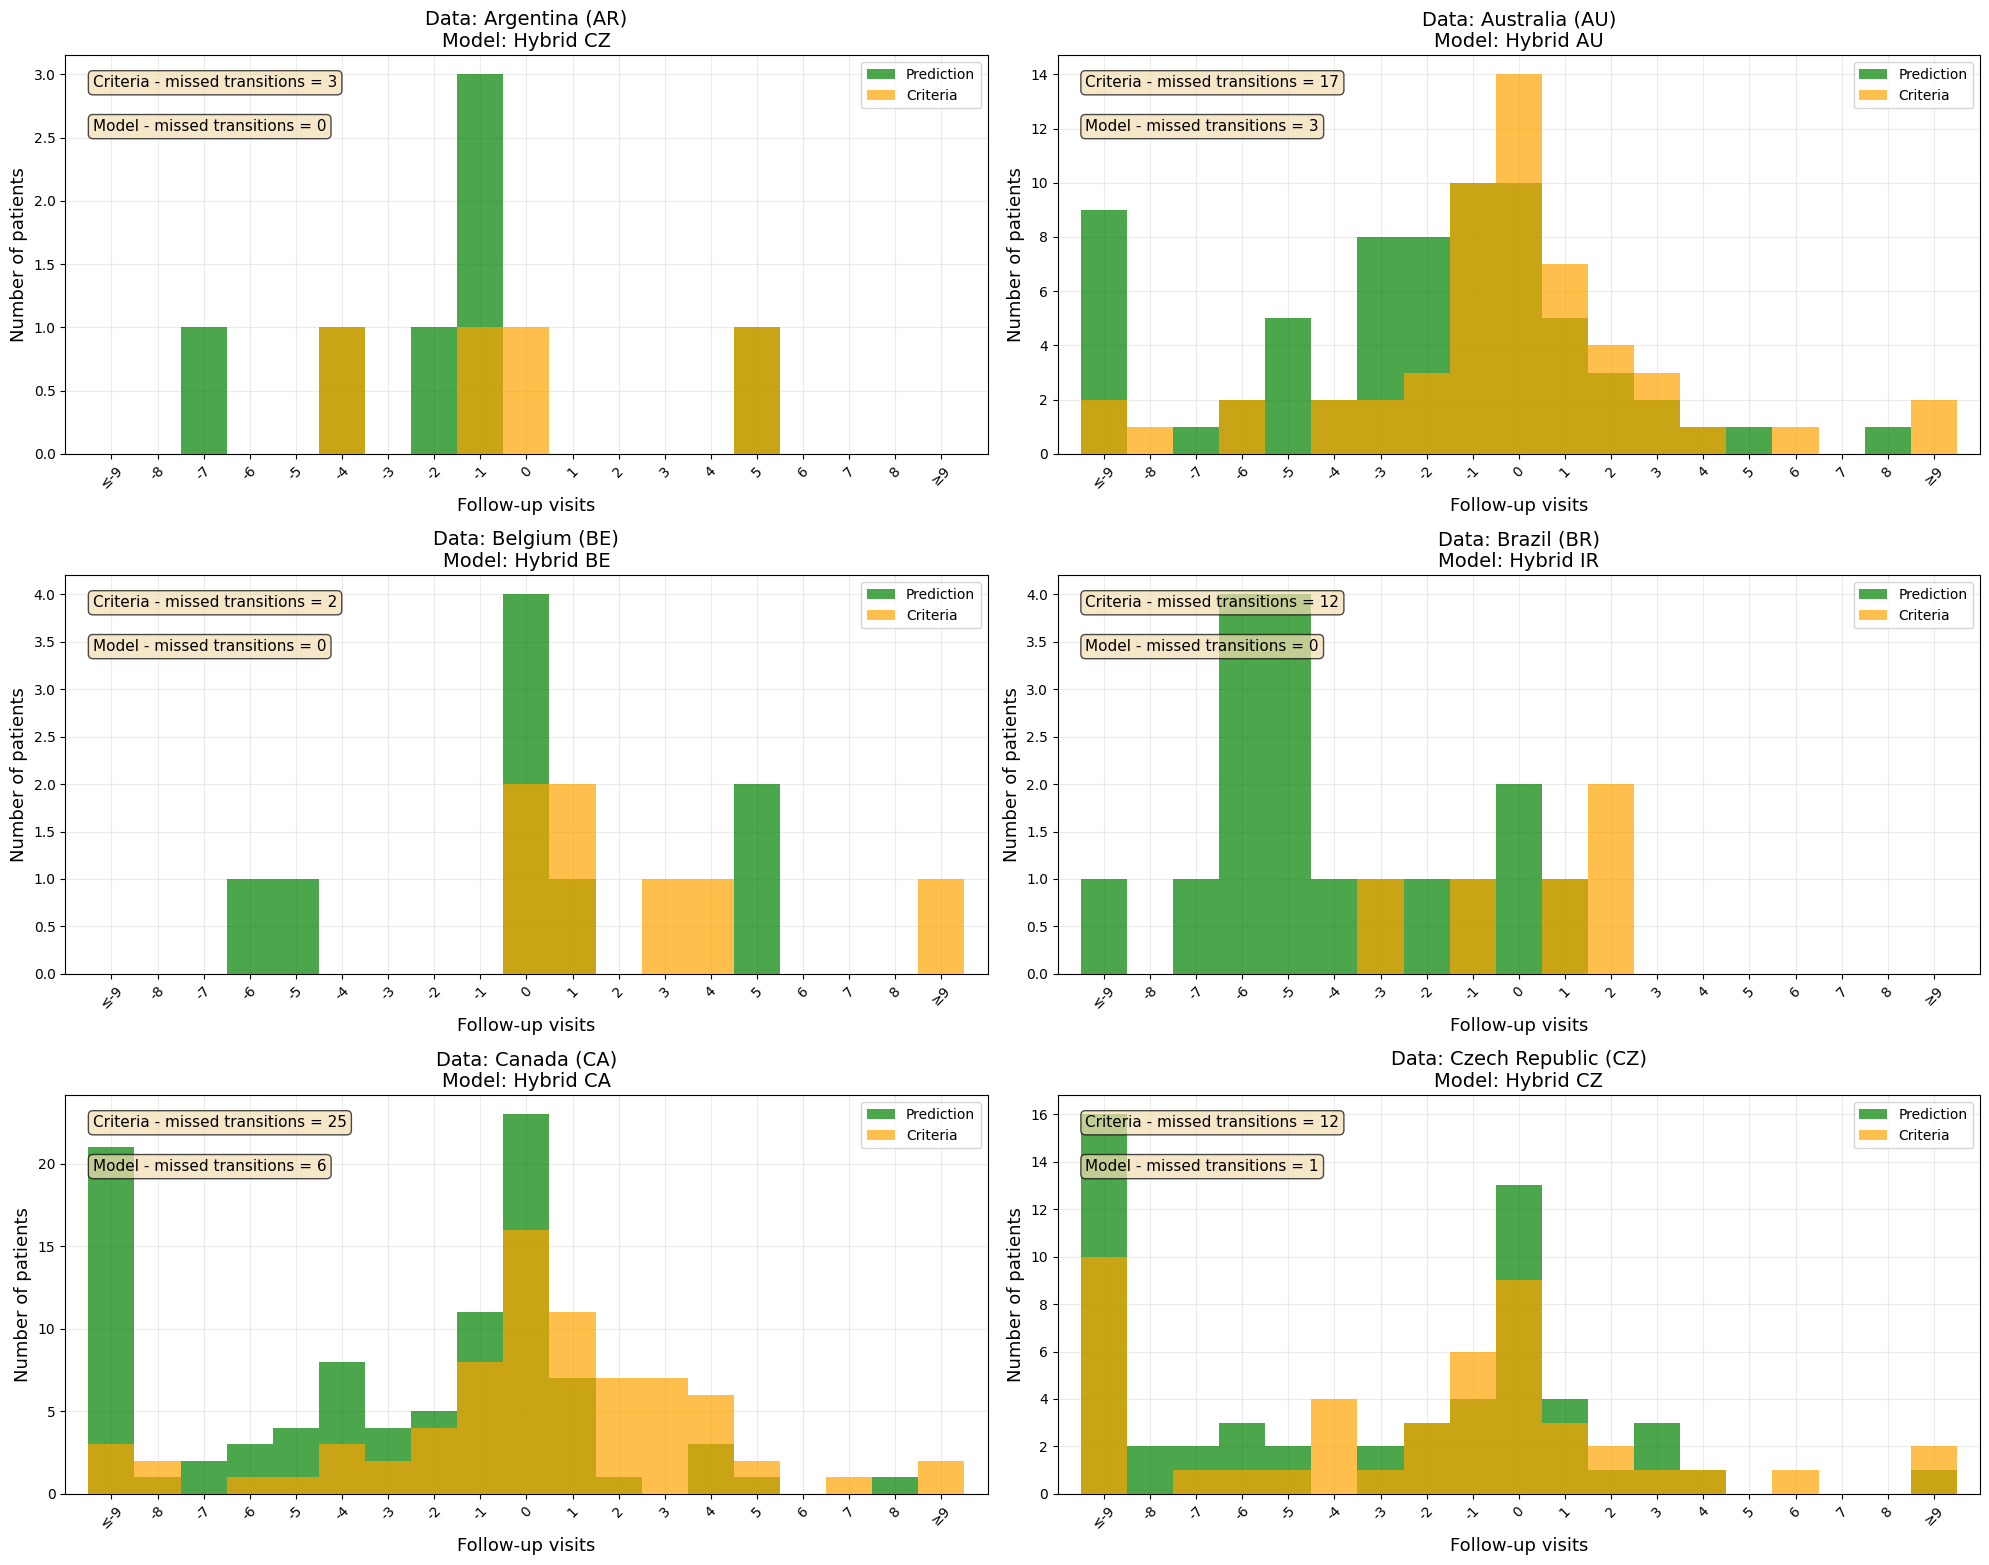

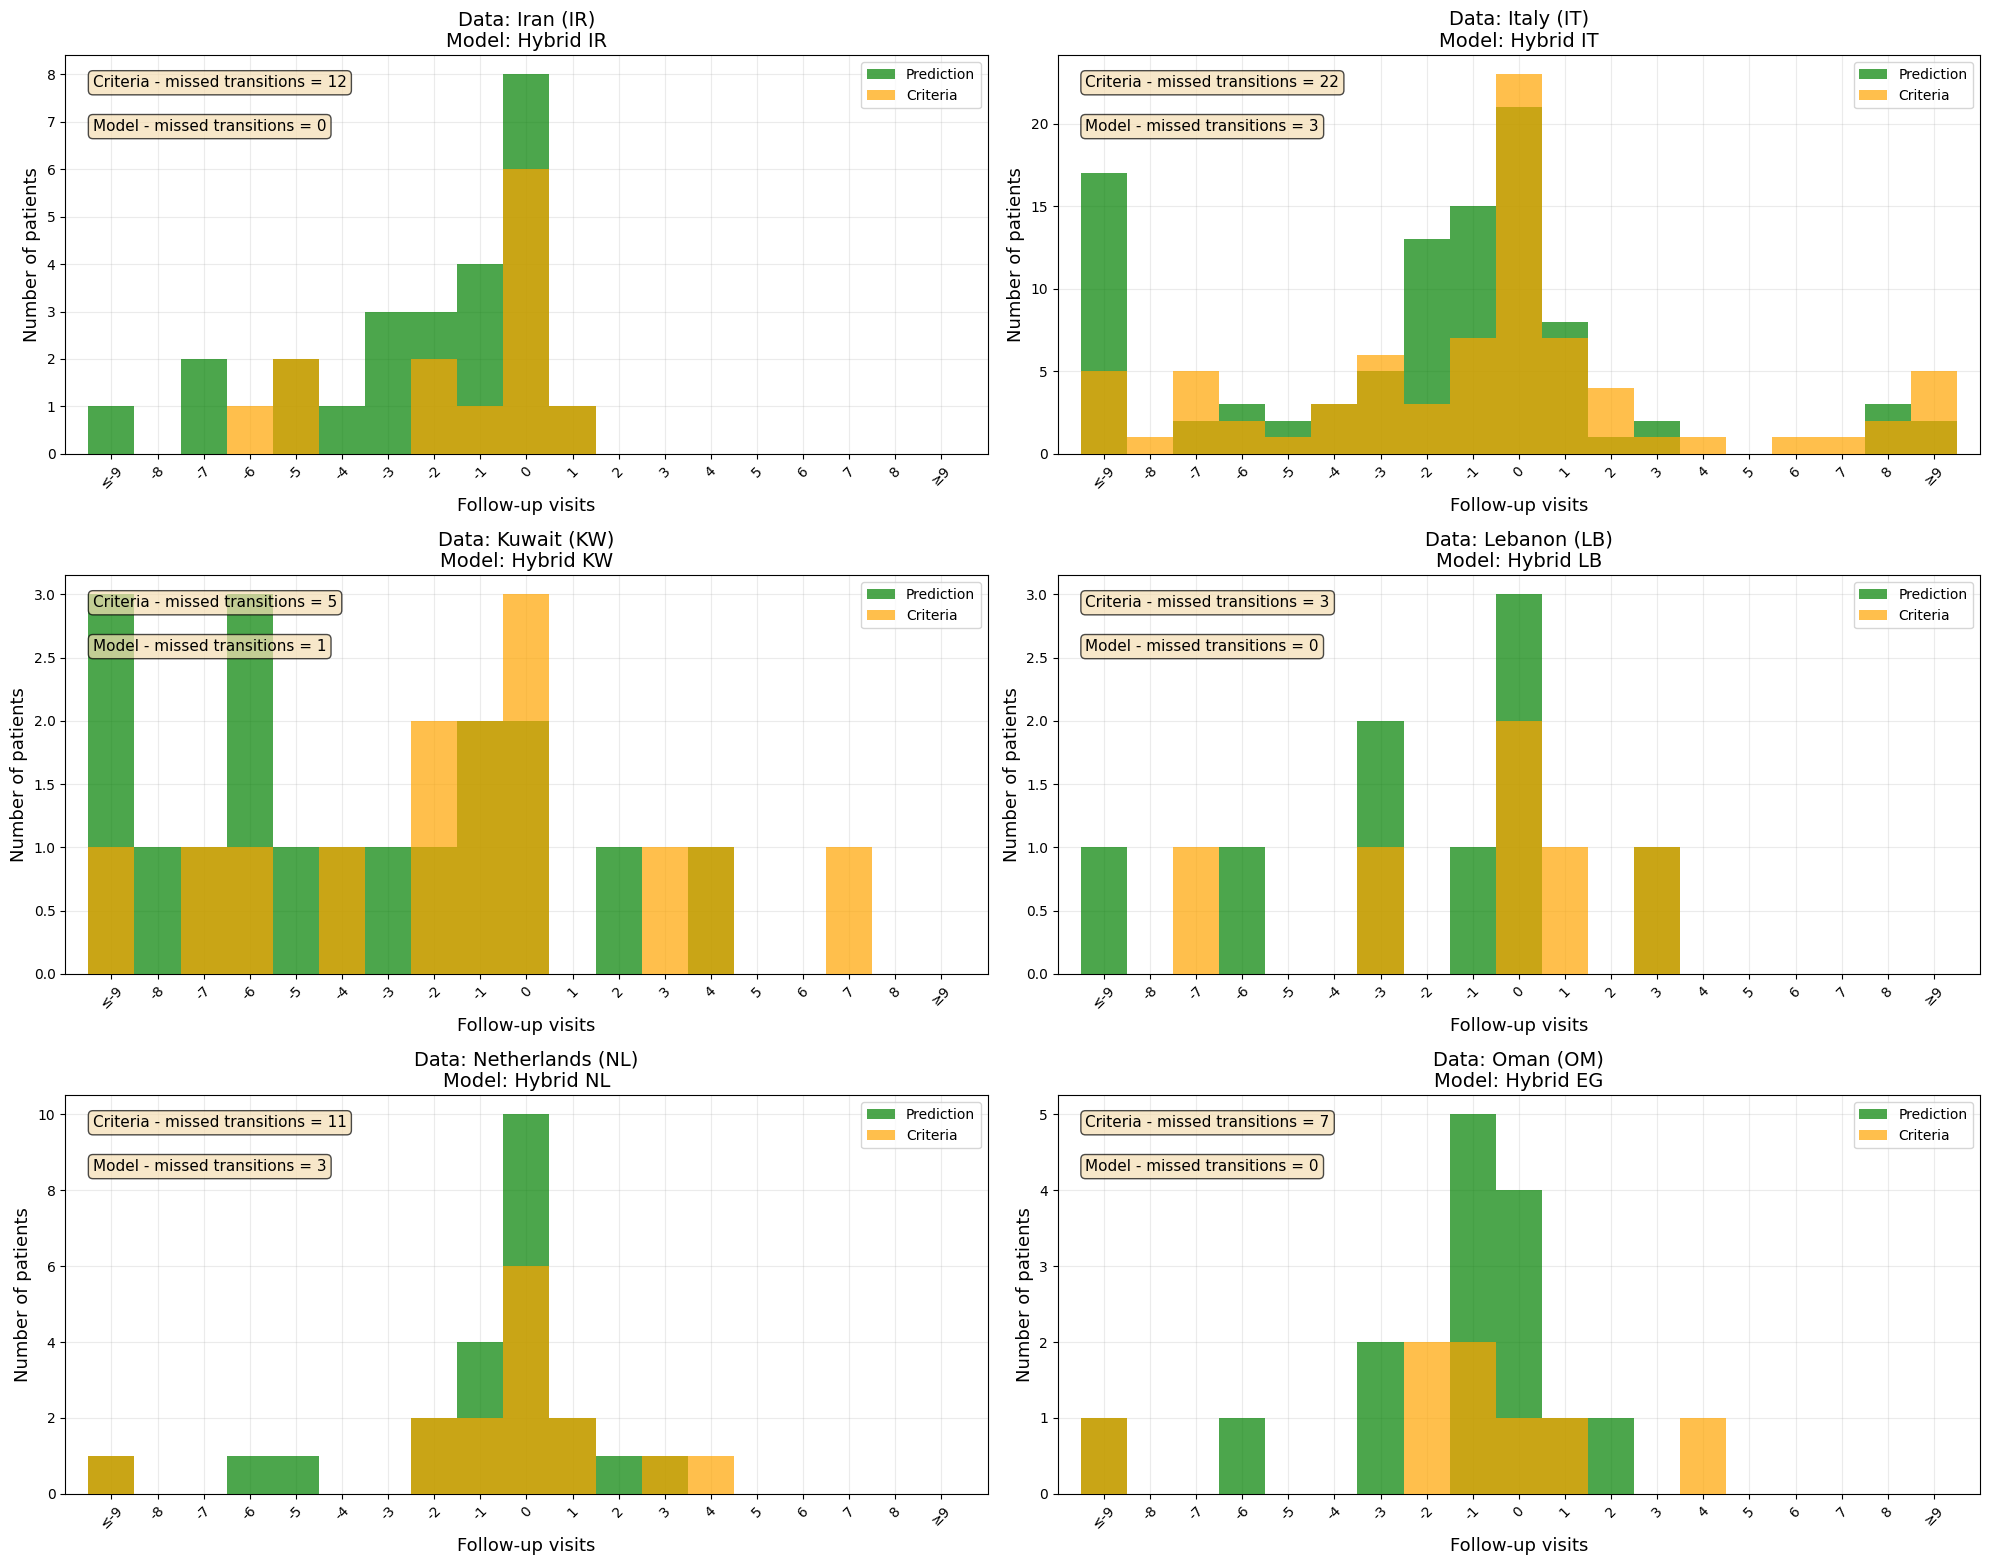

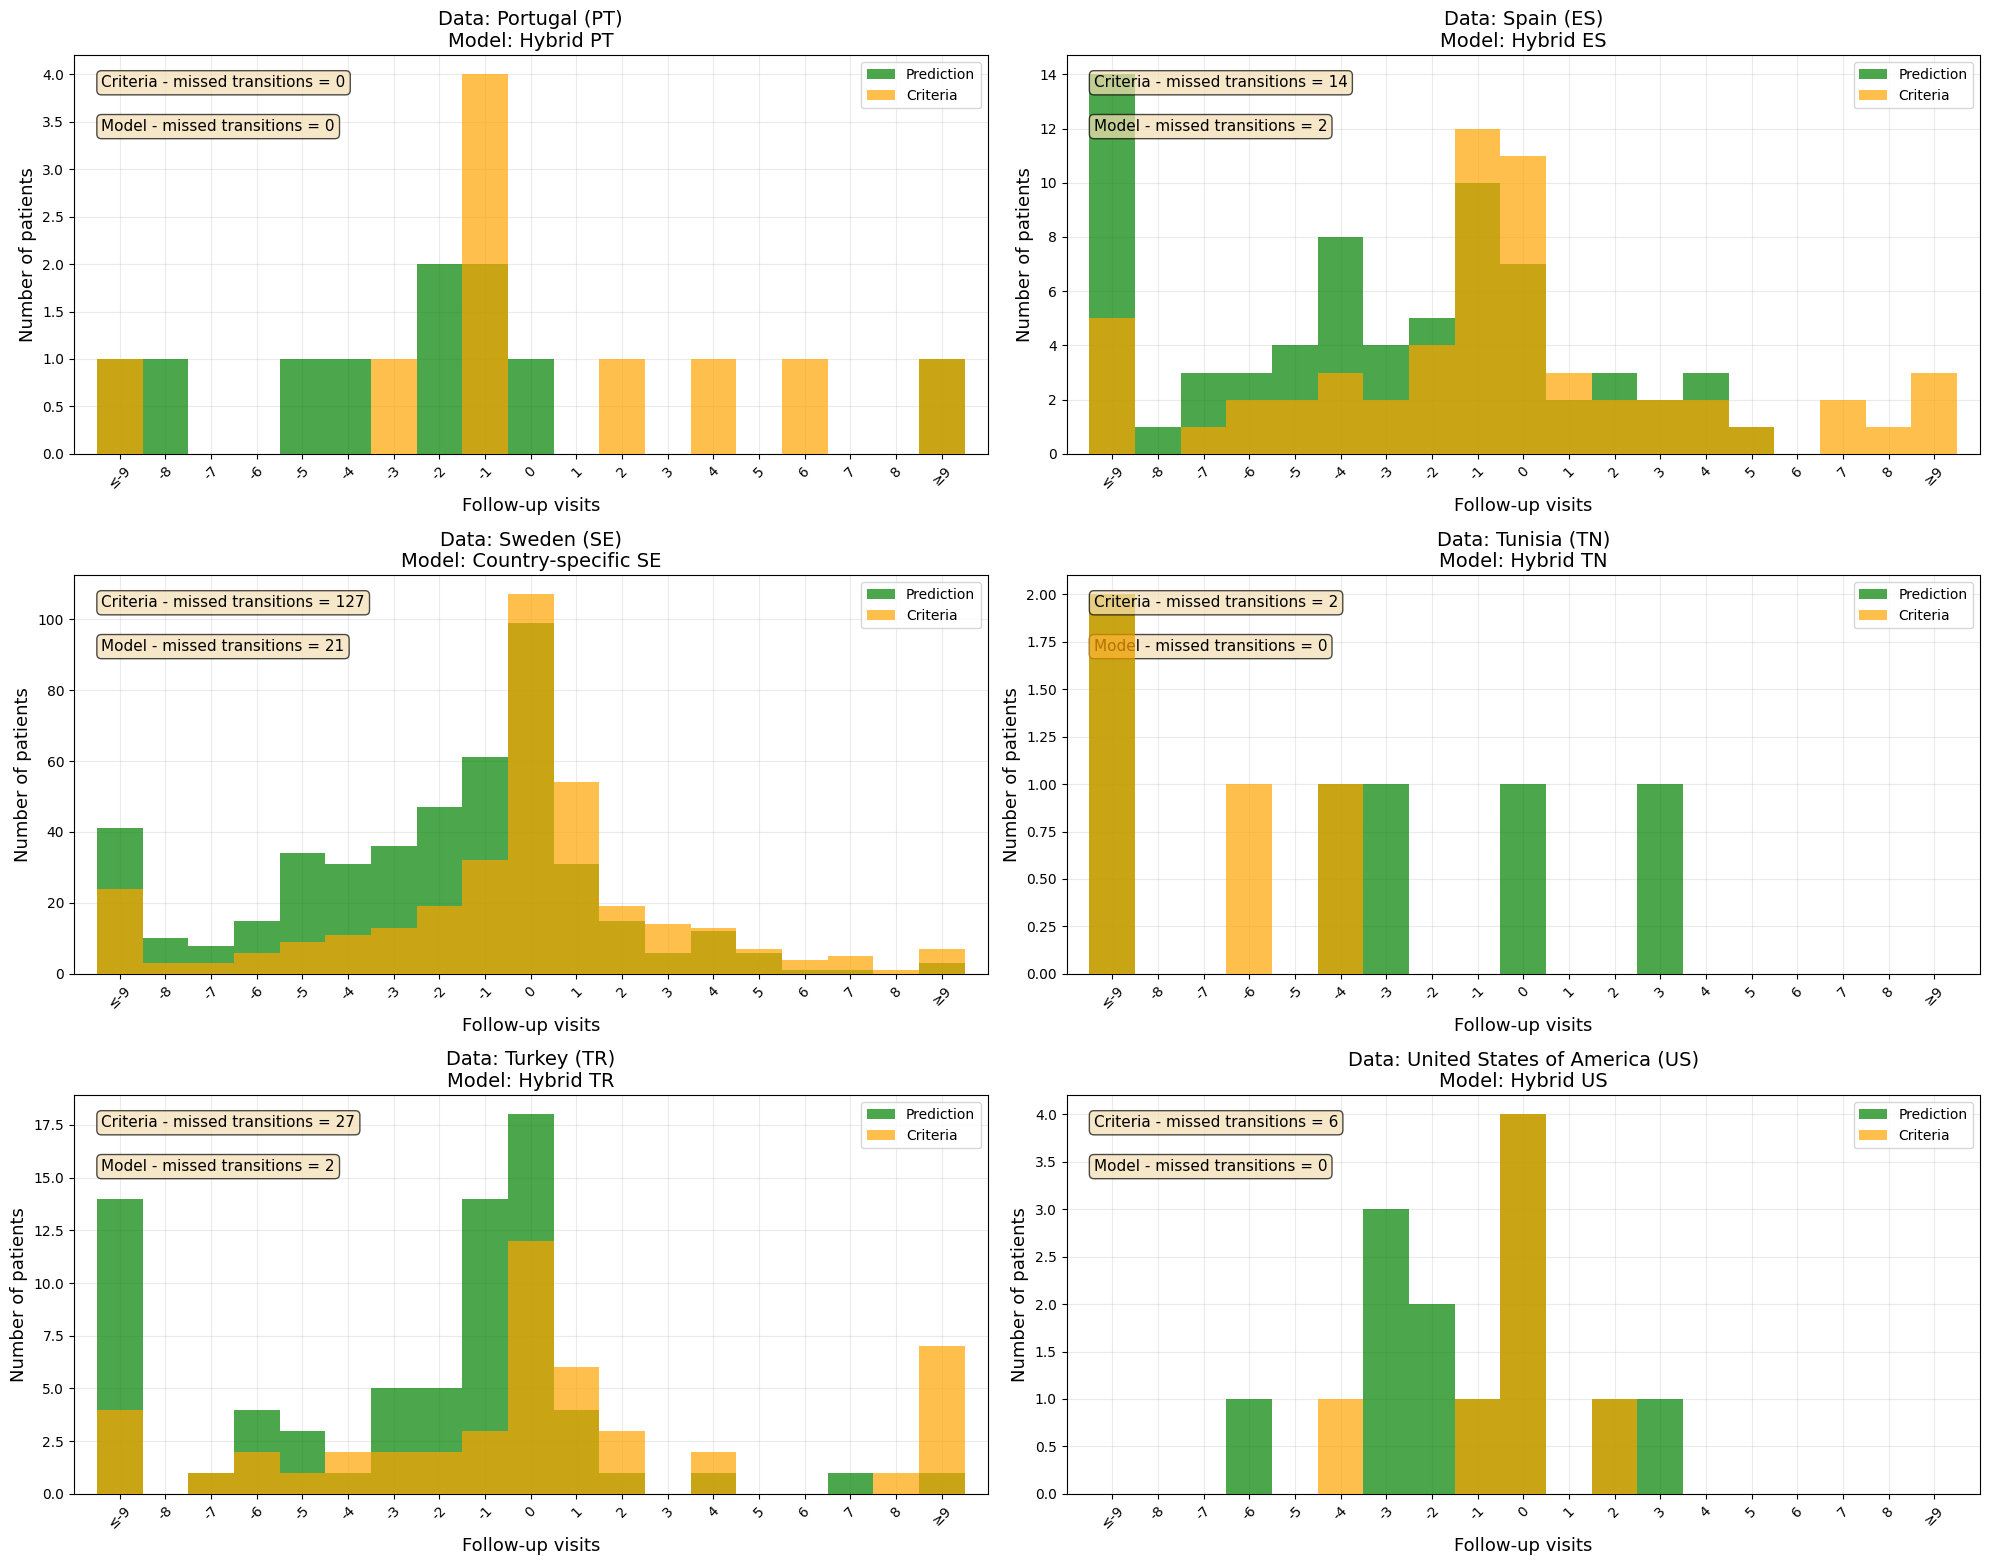

In [17]:
def timing_hist(ax, diffs, missed, color, row, name, clip=9, fontsize=13):
    freq = Counter(np.clip(diffs, -clip, clip))
    ax.bar(list(freq), list(freq.values()), width=1, color=color, alpha=0.7, zorder=3)
    ax.text(0.03, 0.95 - 0.11 * row, f"{name} - missed transitions = {missed}", transform=ax.transAxes,
            fontsize=fontsize - 2, va="top", bbox={"boxstyle": "round", "facecolor": "wheat", "alpha": 0.7})
    ticks = np.arange(-clip, clip + 1)
    ax.set_xticks(ticks, [f"≤{-clip}" if t == -clip else f"≥{clip}" if t == clip else str(t) for t in ticks], rotation=45)
    ax.set_xlim(-clip - 1, clip + 1)
    ax.grid(True, alpha=0.25)
    ax.set_xlabel("Follow-up visits", fontsize=fontsize)
    ax.set_ylabel("Number of patients", fontsize=fontsize)


for i in range(0, len(timing_countries), 6):
    batch = timing_countries[i:i + 6]
    fig, axes = plt.subplots(3, 2, figsize=(20, 15.75))
    axes = axes.flatten()
    for ax, cc in zip(axes, batch):
        lor, pred = visit_diffs.get(cc, {}).get("lor_diff", []), visit_diffs.get(cc, {}).get("pred_diff", [])
        n = cm.loc[cc, "transition_gt"]
        timing_hist(ax, pred, n - len(pred), "green", 1, "Model")
        timing_hist(ax, lor, n - len(lor), "orange", 0, "Criteria")
        ax.set_title(f"Data: {label(cc)}\nModel: {assignment[cc]}", fontsize=14)
        ax.legend(handles=[Patch(facecolor="green", alpha=0.7, label="Prediction"),
                           Patch(facecolor="orange", alpha=0.7, label="Criteria")], loc="upper right")
    for ax in axes[len(batch):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/supp_figs6-8_transition_timing_page{i // 6 + 1}.png", dpi=300, bbox_inches="tight")
    plt.show()